# CSE422 Lab Project: Hotel Booking Reservation Status Classification

## Using Machine Learning Techniques

---

## 1. Introduction

**Project Aim:** Predict the final reservation status (Check-Out, Canceled, No-Show) of hotel bookings using machine learning.

**Problem Statement:** Build and compare multiple classification models to determine which booking and guest features best predict whether a reservation will be completed, canceled, or result in a no-show.

**Motivation:** Accurately predicting cancellations and no-shows helps hotels optimize overbooking strategies, staffing, and revenue management.

In [ ]:
# ============================================================
# STEP 1: IMPORT LIBRARIES
# ============================================================

# Data handling
import pandas as pd
import numpy as np

# Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# Warning control
import warnings
warnings.filterwarnings('ignore')

# Dataset splitting
from sklearn.model_selection import train_test_split

# Preprocessing and encoding
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    LabelEncoder,
    label_binarize
)

# Preprocessing pipelines
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Feature selection
from sklearn.feature_selection import SelectKBest, f_classif

# Supervised classification models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

# Unsupervised learning
from sklearn.cluster import KMeans

# Dimensionality reduction
from sklearn.decomposition import TruncatedSVD, PCA

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score,
    silhouette_score,
    davies_bouldin_score
)

# Plotting style
sns.set_style('whitegrid')

# Show all DataFrame columns when needed
pd.set_option('display.max_columns', None)

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully.")
print("Random state:", RANDOM_STATE)

All libraries imported successfully.
Random state: 42


## 2. Dataset Description

### 2.1 Dataset Overview
Load the Hotel Booking Demand dataset and get an initial look at its size and structure.

In [ ]:
# ============================================================
# STEP 2: LOAD DATASET
# ============================================================

from google.colab import files

# Upload the CSV file
uploaded = files.upload()

# Get the actual uploaded filename
dataset_filename = next(iter(uploaded.keys()))

# Load the uploaded CSV
df = pd.read_csv(dataset_filename)

print("Dataset loaded successfully.")
print("File:", dataset_filename)
print("Dataset shape:", df.shape)
print("Number of samples:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Saving hotel_bookings (1).csv to hotel_bookings (1).csv
Dataset loaded successfully.
File: hotel_bookings (1).csv
Dataset shape: (119390, 32)
Number of samples: 119390
Number of columns: 32


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
#Dataset Description
# ============================================================
# STEP 4: DATASET DESCRIPTION
# ============================================================

print("Number of data points:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")

for i, column in enumerate(df.columns, start=1):
    print(i, column)

Number of data points: 119390
Number of columns: 32

Column names:
1 hotel
2 is_canceled
3 lead_time
4 arrival_date_year
5 arrival_date_month
6 arrival_date_week_number
7 arrival_date_day_of_month
8 stays_in_weekend_nights
9 stays_in_week_nights
10 adults
11 children
12 babies
13 meal
14 country
15 market_segment
16 distribution_channel
17 is_repeated_guest
18 previous_cancellations
19 previous_bookings_not_canceled
20 reserved_room_type
21 assigned_room_type
22 booking_changes
23 deposit_type
24 agent
25 company
26 days_in_waiting_list
27 customer_type
28 adr
29 required_car_parking_spaces
30 total_of_special_requests
31 reservation_status
32 reservation_status_date


In [ ]:
#Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
#Statistical description
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [ ]:
#Numerical and categorical features
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=['object']
).columns.tolist()

print("Number of numerical columns:", len(numerical_columns))
print(numerical_columns)

print("\nNumber of categorical columns:", len(categorical_columns))
print(categorical_columns)

Number of numerical columns: 20
['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Number of categorical columns: 12
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


In [ ]:
#Define and examine target
target = 'reservation_status'

print("Target variable:", target)

print("\nUnique target classes:")
print(df[target].unique())

print("\nNumber of classes:")
print(df[target].nunique())

print("\nClass counts:")
print(df[target].value_counts())

print("\nClass percentages:")
print(
    (df[target].value_counts(normalize=True) * 100)
    .round(2)
)

Target variable: reservation_status

Unique target classes:
['Check-Out' 'Canceled' 'No-Show']

Number of classes:
3

Class counts:
reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64

Class percentages:
reservation_status
Check-Out    62.96
Canceled     36.03
No-Show       1.01
Name: proportion, dtype: float64


### 2.2 Imbalanced Dataset Analysis
Check whether the target classes (Check-Out, Canceled, No-Show) are balanced or skewed.

,count
reservation_status,
Check-Out,75166
Canceled,43017
No-Show,1207


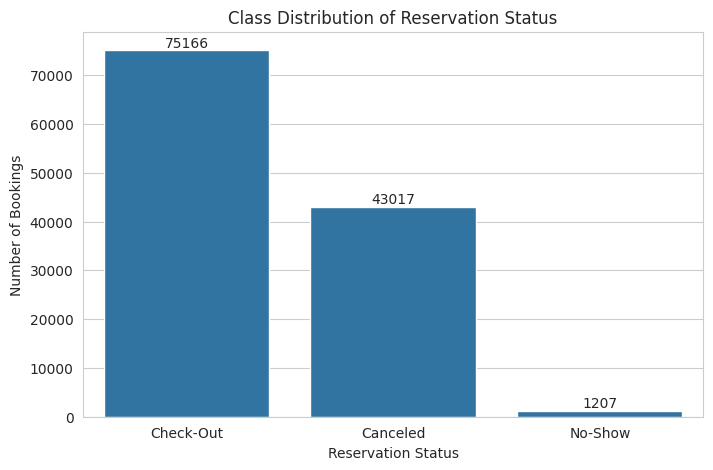

In [ ]:
#Class Distribution / Imbalance Checking
# ============================================================
# STEP 6: CLASS DISTRIBUTION
# ============================================================

class_counts = df[target].value_counts()

display(class_counts)

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x=target,
    order=class_counts.index
)

plt.title('Class Distribution of Reservation Status')
plt.xlabel('Reservation Status')
plt.ylabel('Number of Bookings')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

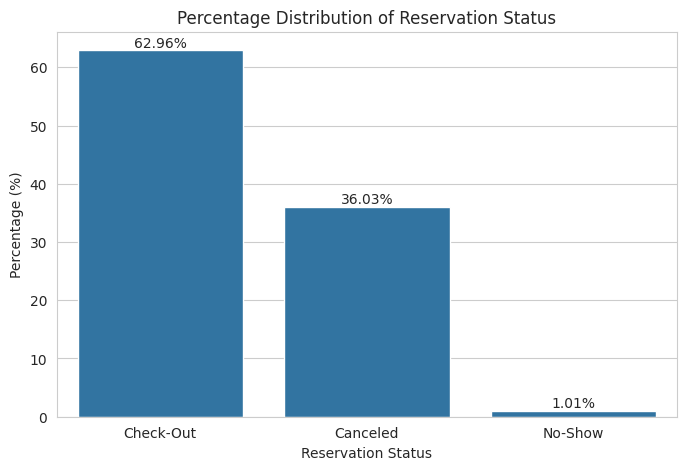

In [ ]:
#Percentage chart
class_percentage = (
    df[target]
    .value_counts(normalize=True)
    .mul(100)
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_percentage.index,
    y=class_percentage.values
)

plt.title('Percentage Distribution of Reservation Status')
plt.xlabel('Reservation Status')
plt.ylabel('Percentage (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%')

plt.show()

### 2.3 Missing Value Analysis
Identify which columns have missing values and how severe the missingness is.

In [ ]:
#Missing Value Analysis
# ============================================================
# MISSING VALUE ANALYSIS
# ============================================================

missing_values = df.isnull().sum()

missing_values = (
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

print("Missing values:")
display(missing_values)

Missing values:


,0
company,112593
agent,16340
country,488
children,4


In [ ]:
#Percentage
missing_percentage = (
    df.isnull().mean() * 100
)

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

missing_summary = (
    missing_summary[
        missing_summary['Missing Values'] > 0
    ]
    .sort_values(
        by='Missing Percentage',
        ascending=False
    )
)

display(missing_summary)

,Missing Values,Missing Percentage
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


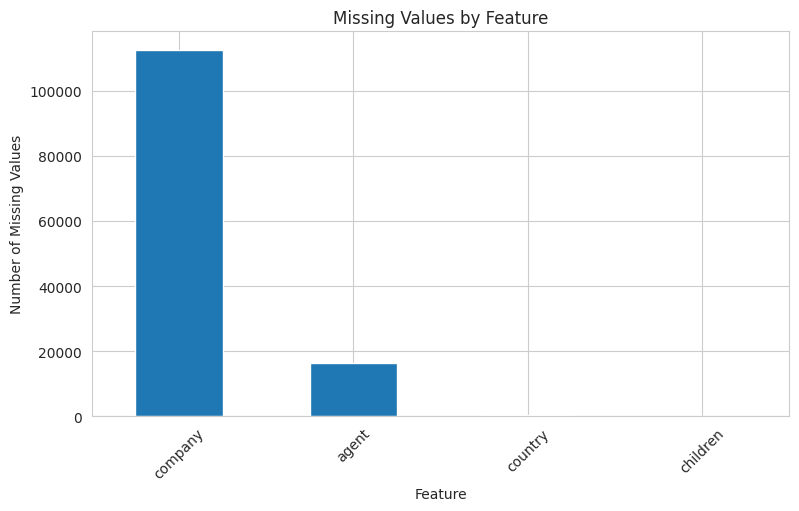

In [ ]:
#Plot
plt.figure(figsize=(9, 5))

missing_values.plot(kind='bar')

plt.title('Missing Values by Feature')
plt.xlabel('Feature')
plt.ylabel('Number of Missing Values')

plt.xticks(rotation=45)

plt.show()

### 2.4 Exploratory Data Analysis (EDA)
Visualize how reservation status varies across hotel type, arrival month, market segment, deposit type, customer type, lead time, ADR, and special requests.

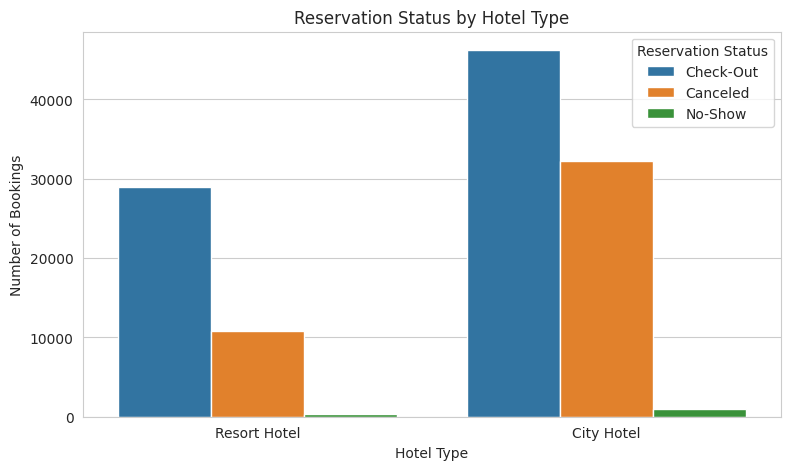

In [ ]:
#Reservation status by hotel type
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='hotel',
    hue='reservation_status'
)

plt.title('Reservation Status by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')

plt.legend(title='Reservation Status')

plt.show()

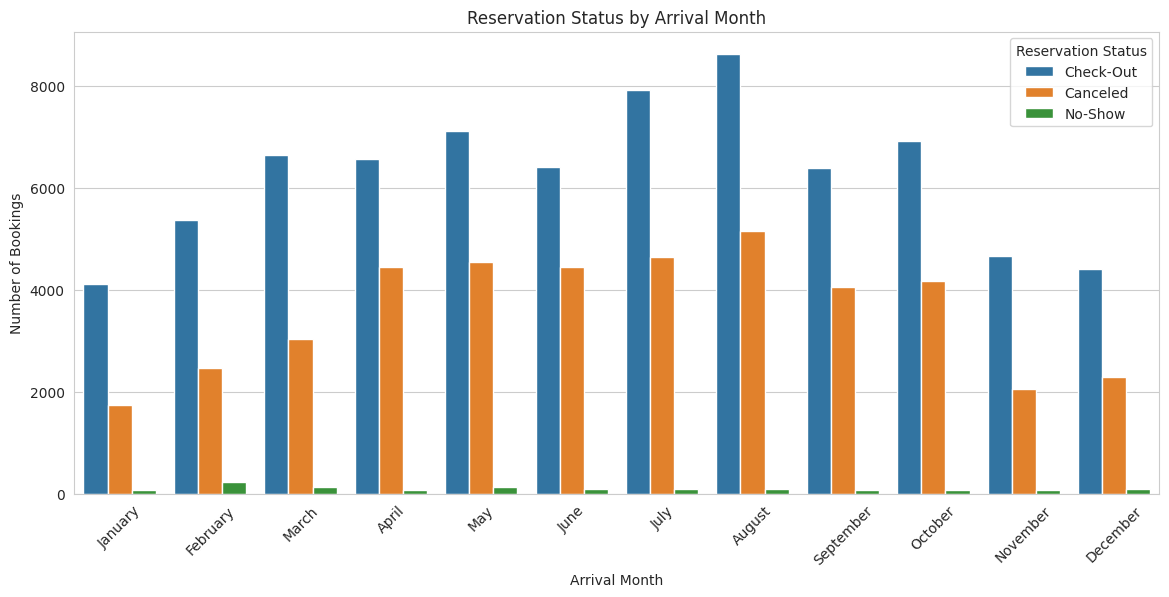

In [ ]:
#Reservation status by arrival month
month_order = [
    'January',
    'February',
    'March',
    'April',
    'May',
    'June',
    'July',
    'August',
    'September',
    'October',
    'November',
    'December'
]

plt.figure(figsize=(14, 6))

sns.countplot(
    data=df,
    x='arrival_date_month',
    hue='reservation_status',
    order=month_order
)

plt.title('Reservation Status by Arrival Month')
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)

plt.legend(title='Reservation Status')

plt.show()

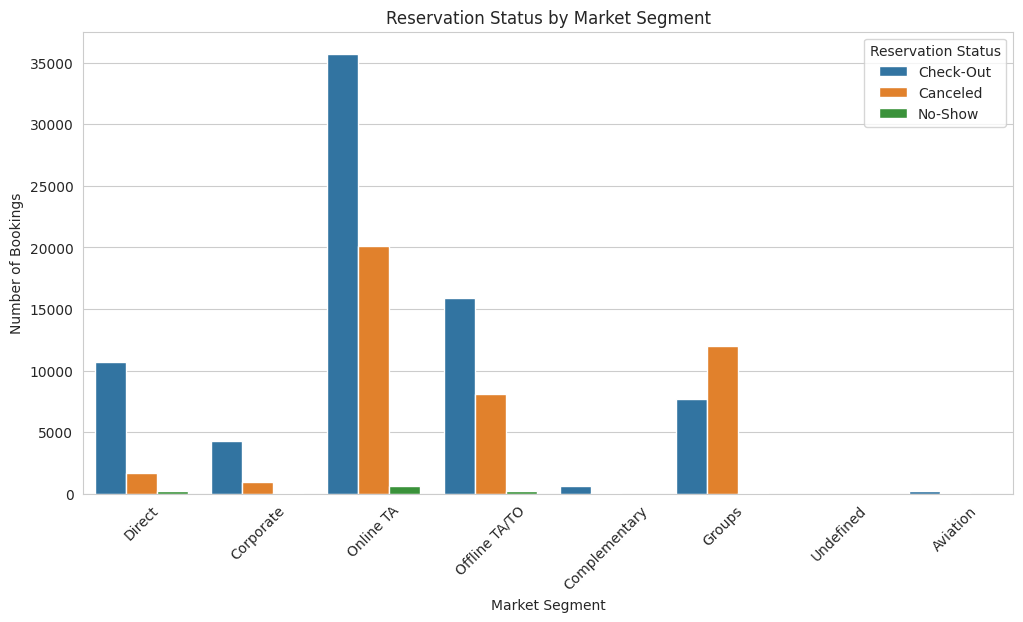

In [ ]:
#Market segment
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='market_segment',
    hue='reservation_status'
)

plt.title('Reservation Status by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)

plt.legend(title='Reservation Status')

plt.show()

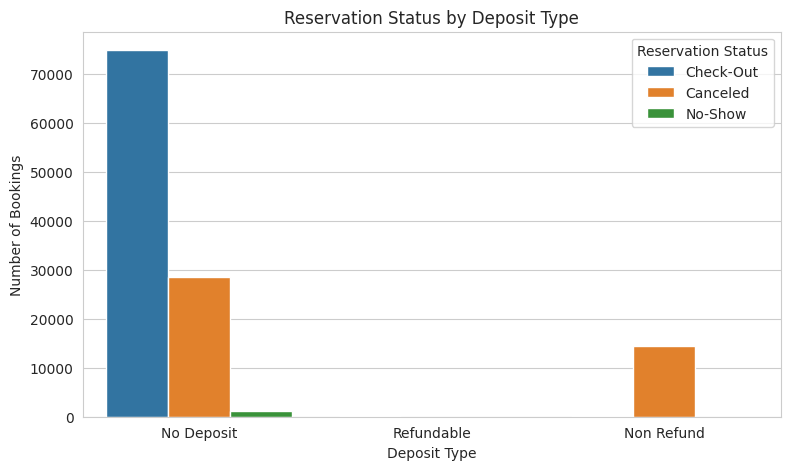

In [ ]:
#Deposit type
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='deposit_type',
    hue='reservation_status'
)

plt.title('Reservation Status by Deposit Type')
plt.xlabel('Deposit Type')
plt.ylabel('Number of Bookings')

plt.legend(title='Reservation Status')

plt.show()

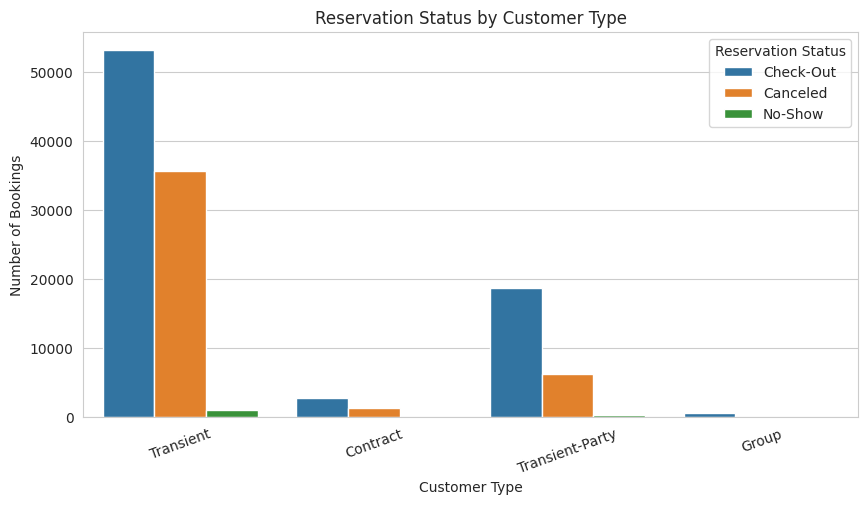

In [ ]:
#Customer type
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='customer_type',
    hue='reservation_status'
)

plt.title('Reservation Status by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=20)

plt.legend(title='Reservation Status')

plt.show()

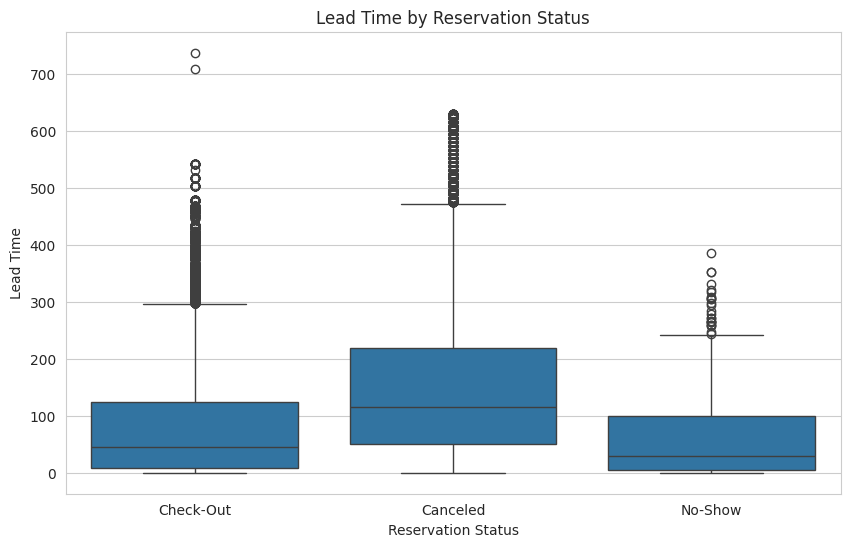

In [ ]:
#Lead time
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='reservation_status',
    y='lead_time'
)

plt.title('Lead Time by Reservation Status')
plt.xlabel('Reservation Status')
plt.ylabel('Lead Time')

plt.show()

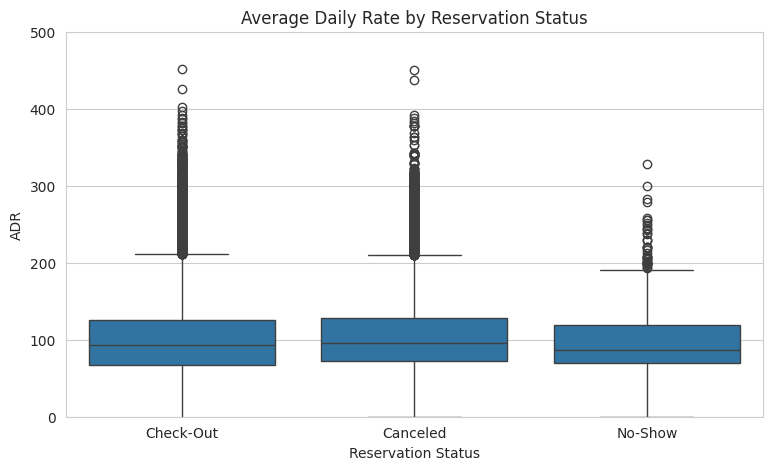

In [ ]:
#ADR
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='reservation_status',
    y='adr'
)


plt.ylim(0, 500)

plt.title('Average Daily Rate by Reservation Status')
plt.xlabel('Reservation Status')
plt.ylabel('ADR')

plt.show()

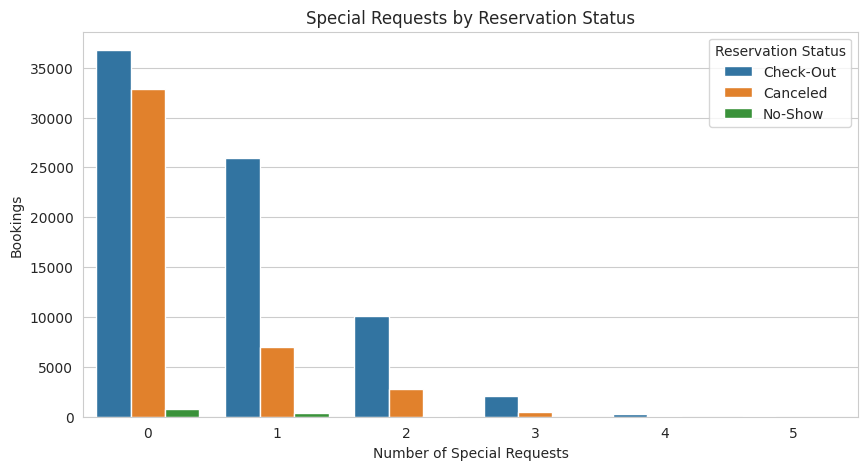

In [ ]:
#Special requests
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='total_of_special_requests',
    hue='reservation_status'
)

plt.title(
    'Special Requests by Reservation Status'
)

plt.xlabel(
    'Number of Special Requests'
)

plt.ylabel('Bookings')

plt.legend(title='Reservation Status')

plt.show()

### 2.5 Correlation Analysis
Examine correlation between features and the (encoded) target to understand which variables are most related to reservation status.

Correlation matrix shape: (32, 32)
Number of features included: 32


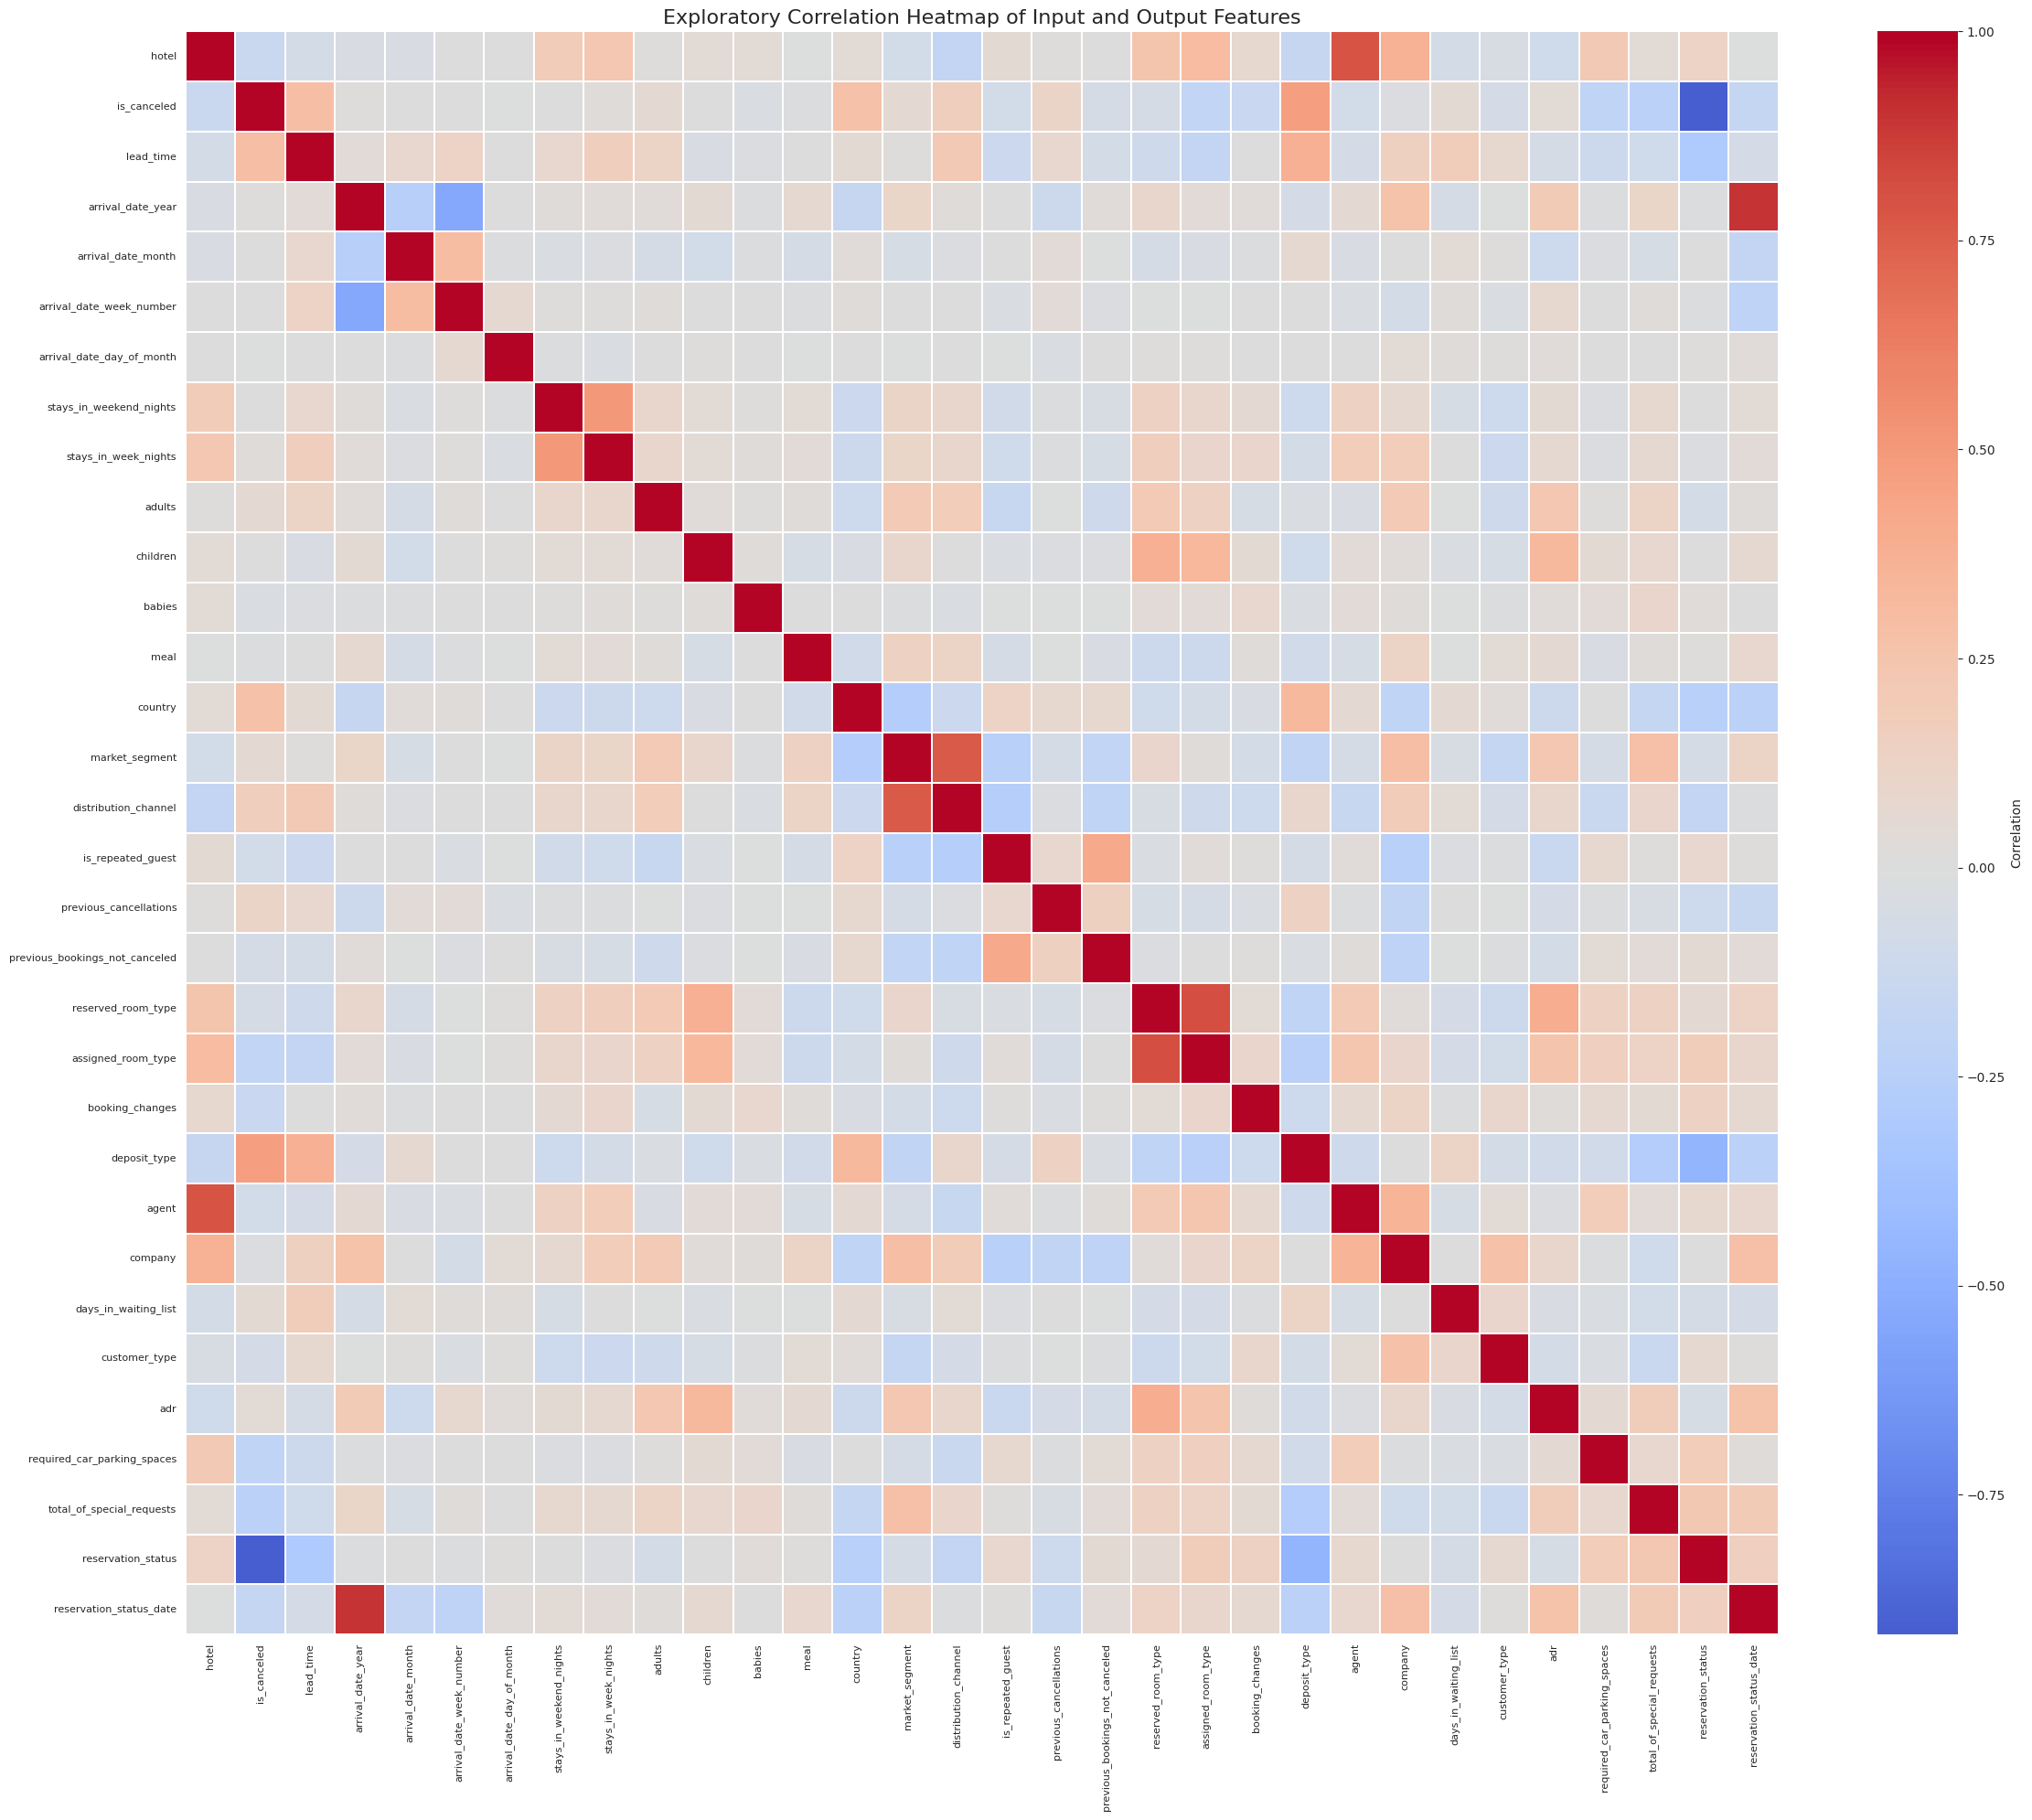

In [ ]:
#correlation cell

# ============================================================
# CORRELATION ANALYSIS INCLUDING CATEGORICAL FEATURES
# ============================================================

# Make a separate copy so the original dataset is not changed
correlation_df = df.copy()

# Store encoders for reference
correlation_encoders = {}

# Encode every categorical column only for correlation analysis
for column in correlation_df.select_dtypes(
    include=['object', 'category']
).columns:

    encoder = LabelEncoder()

    correlation_df[column] = encoder.fit_transform(
        correlation_df[column]
        .fillna('Missing')
        .astype(str)
    )

    correlation_encoders[column] = encoder

# Calculate correlation for all encoded and numerical columns
correlation_matrix = correlation_df.corr(
    numeric_only=True
)

print(
    "Correlation matrix shape:",
    correlation_matrix.shape
)

print(
    "Number of features included:",
    correlation_matrix.shape[1]
)

# Plot the complete correlation heatmap
plt.figure(figsize=(24, 20))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    annot=False,
    linewidths=0.2,
    cbar_kws={'label': 'Correlation'}
)

plt.title(
    'Exploratory Correlation Heatmap of Input and Output Features',
    fontsize=16
)

plt.xticks(
    rotation=90,
    fontsize=8
)

plt.yticks(
    rotation=0,
    fontsize=8
)

plt.tight_layout()
plt.show()

Correlations with reservation_status:


,Correlation with Reservation Status
is_canceled,-0.917196
deposit_type,-0.466185
lead_time,-0.302175
country,-0.245044
total_of_special_requests,0.225674
required_car_parking_spaces,0.179310
assigned_room_type,0.172537
distribution_channel,-0.171330
reservation_status_date,0.156655
booking_changes,0.140799


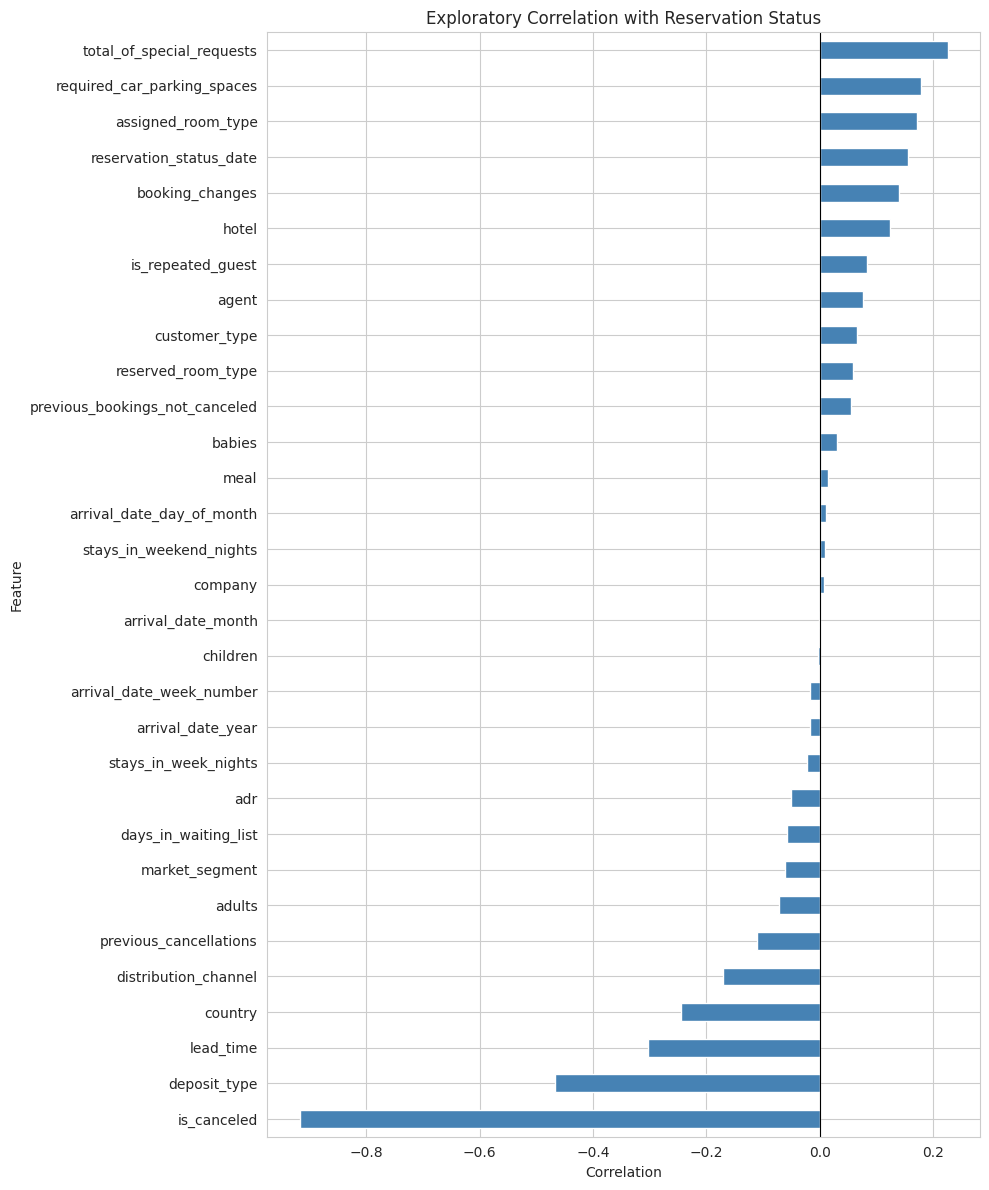


Important note: Label encoding assigns arbitrary numbers to nominal categorical variables. Therefore, categorical correlations are exploratory associations and should not be interpreted as ordinal relationships.


In [ ]:
# ============================================================
# CORRELATION OF FEATURES WITH TARGET
# ============================================================

target_column = 'reservation_status'

# Confirm that the target exists
if target_column not in correlation_matrix.columns:
    raise ValueError(
        f"{target_column} is missing from the "
        "correlation matrix."
    )


target_correlations = (
    correlation_matrix[target_column]
    .drop(target_column)
    .sort_values(
        key=abs,
        ascending=False
    )
)

print(
    "Correlations with reservation_status:"
)

display(
    target_correlations.to_frame(
        name='Correlation with Reservation Status'
    )
)

# Plot target correlations
plt.figure(figsize=(10, 12))

target_correlations.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.axvline(
    x=0,
    color='black',
    linewidth=0.8
)

plt.title(
    'Exploratory Correlation with Reservation Status'
)

plt.xlabel('Correlation')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

print(
    "\nImportant note: Label encoding assigns arbitrary "
    "numbers to nominal categorical variables. Therefore, "
    "categorical correlations are exploratory associations "
    "and should not be interpreted as ordinal relationships."
)

## 3. Dataset Pre-processing

### 3.1 Handling Missing Values, Invalid Rows & Leakage Columns
Drop high-missing columns, impute remaining missing values, remove invalid bookings, and drop columns that leak the target (`is_canceled`, `reservation_status_date`, `assigned_room_type`).

In [ ]:
#Create clean dataset
# ============================================================
# STEP 10: DATA PREPROCESSING
# ============================================================

df_clean = df.copy()

In [ ]:
#Very high missing values in company
company_missing_percentage = (
    df_clean['company']
    .isnull()
    .mean() * 100
)

print(
    "Missing percentage in company:",
    round(company_missing_percentage, 2),
    "%"
)

Missing percentage in company: 94.31 %


In [ ]:
#extremely high,
df_clean.drop(
    columns=['company'],
    inplace=True
)

print("company column removed.")

company column removed.


In [ ]:
# ============================================================
# MISSING AGENT IDS
# ============================================================

# Treat agent IDs as categorical identifiers

df_clean['agent'] = (
    df_clean['agent']
    .apply(
        lambda value:
            'Unknown'
            if pd.isna(value)
            else str(int(value))
    )
)

print(
    "Agent missing values:",
    df_clean['agent'].isnull().sum()
)

print(
    "Number of unique agent categories:",
    df_clean['agent'].nunique()
)

print(
    "Example agent categories:",
    df_clean['agent'].unique()[:10]
)

Agent missing values: 0
Number of unique agent categories: 334
Example agent categories: ['Unknown' '304' '240' '303' '15' '241' '8' '250' '115' '5']


In [ ]:
#Missing country
# ============================================================
# STEP 10.3: MISSING COUNTRY
# ============================================================

print("Missing country values:", df_clean['country'].isnull().sum())

Missing country values: 488


In [ ]:
#Missing children
# ============================================================
# STEP 10.4: MISSING CHILDREN
# ============================================================

print("Missing children values:", df_clean['children'].isnull().sum())

Missing children values: 4


In [ ]:
# ============================================================
# MISSING-VALUE TREATMENT PLAN
# ============================================================

print("Missing-value solutions:")

print(
    "1. company: dropped because approximately 94% is missing."
)

print(
    "2. agent: missing IDs represented as the category 'Unknown'."
)

print(
    "3. country: imputed with the most frequent category "
    "inside the preprocessing pipeline."
)

print(
    "4. children: imputed with the median "
    "inside the preprocessing pipeline."
)

print(
    "5. Pipeline imputers are fitted only on training data "
    "to prevent data leakage."
)

Missing-value solutions:
1. company: dropped because approximately 94% is missing.
2. agent: missing IDs represented as the category 'Unknown'.
3. country: imputed with the most frequent category inside the preprocessing pipeline.
4. children: imputed with the median inside the preprocessing pipeline.
5. Pipeline imputers are fitted only on training data to prevent data leakage.


In [ ]:
# ============================================================
# STEP 10.5: REMOVE TARGET AND TEMPORAL LEAKAGE
# ============================================================

leakage_columns = [
    'is_canceled',
    'reservation_status_date',
    'assigned_room_type'
]

# Keep only columns that actually exist
existing_leakage_columns = [
    column
    for column in leakage_columns
    if column in df_clean.columns
]

df_clean.drop(
    columns=existing_leakage_columns,
    inplace=True
)

print("Removed leakage columns:")
print(existing_leakage_columns)

print("\nLeakage-column verification:")

for column in leakage_columns:
    print(
        column,
        "present:",
        column in df_clean.columns
    )

print("\nRemaining number of columns:", df_clean.shape[1])
print("Remaining columns:")
print(df_clean.columns.tolist())

Removed leakage columns:
['is_canceled', 'reservation_status_date', 'assigned_room_type']

Leakage-column verification:
is_canceled present: False
reservation_status_date present: False
assigned_room_type present: False

Remaining number of columns: 28
Remaining columns:
['hotel', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'booking_changes', 'deposit_type', 'agent', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status']


In [ ]:
#Invalid bookings
invalid_booking_mask = (
    (df_clean['adults'] == 0) &
    (df_clean['children'].fillna(0) == 0) &
    (df_clean['babies'] == 0)
)

print(
    "Number of bookings with zero guests:",
    invalid_booking_mask.sum()
)

Number of bookings with zero guests: 180


In [ ]:
df_clean = (
    df_clean.loc[
        ~invalid_booking_mask
    ]
    .copy()
)

print(
    "Dataset shape after removing invalid bookings:",
    df_clean.shape
)

Dataset shape after removing invalid bookings: (119210, 28)


In [ ]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

# Total number of nights
df_clean['total_nights'] = (
    df_clean['stays_in_weekend_nights'] +
    df_clean['stays_in_week_nights']
)

# Total number of guests
df_clean['total_guests'] = (
    df_clean['adults'] +
    df_clean['children'].fillna(0) +
    df_clean['babies']
)

# Whether children or babies are included in the booking
df_clean['is_family'] = (
    (
        df_clean['children'].fillna(0) +
        df_clean['babies']
    ) > 0
).astype(int)

print("Feature engineering completed.")

print(
    df_clean[
        [
            'total_nights',
            'total_guests',
            'is_family'
        ]
    ].head()
)

print(
    "\nDataset shape after feature engineering:",
    df_clean.shape
)

Feature engineering completed.
   total_nights  total_guests  is_family
0             0           2.0          0
1             0           2.0          0
2             1           1.0          0
3             1           1.0          0
4             2           2.0          0

Dataset shape after feature engineering: (119210, 31)


## 4. Dataset Splitting
Separate features (X) and target (y), then perform a stratified train-test split so all reservation status classes are represented proportionally in both sets.

In [ ]:
#Define X and y
# ============================================================
# STEP 11: DEFINE INPUT AND TARGET
# ============================================================

X = df_clean.drop(
    columns=['reservation_status']
)

y = df_clean['reservation_status']

print("Input X shape:", X.shape)
print("Target y shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Input X shape: (119210, 30)
Target y shape: (119210,)

Target classes:
reservation_status
Check-Out    75011
Canceled     42993
No-Show       1206
Name: count, dtype: int64


In [ ]:
#Train-Test Split
# ============================================================
# STEP 12: TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train_text, y_test_text = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(
    "Training data:",
    X_train.shape
)

print(
    "Testing data:",
    X_test.shape
)

Training data: (95368, 30)
Testing data: (23842, 30)


In [ ]:
#Check proportions
print("Training class distribution:")

print(
    y_train_text
    .value_counts(normalize=True)
    .round(4)
)

print("\nTesting class distribution:")

print(
    y_test_text
    .value_counts(normalize=True)
    .round(4)
)

Training class distribution:
reservation_status
Check-Out    0.6292
Canceled     0.3606
No-Show      0.0101
Name: proportion, dtype: float64

Testing class distribution:
reservation_status
Check-Out    0.6292
Canceled     0.3607
No-Show      0.0101
Name: proportion, dtype: float64


In [ ]:
#Encode target labels
# ============================================================
# TARGET ENCODING
# ============================================================

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(
    y_train_text
)

y_test = label_encoder.transform(
    y_test_text
)

print(
    "Target classes:",
    label_encoder.classes_
)

print("\nClass mapping:")

for i, class_name in enumerate(
    label_encoder.classes_
):
    print(i, "=", class_name)

Target classes: ['Canceled' 'Check-Out' 'No-Show']

Class mapping:
0 = Canceled
1 = Check-Out
2 = No-Show


In [ ]:
#Identify numerical and categorical features
numeric_features = (
    X_train
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)

categorical_features = (
    X_train
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

print(
    "Number of numerical features:",
    len(numeric_features)
)

print(numeric_features)

print(
    "\nNumber of categorical features:",
    len(categorical_features)
)

print(categorical_features)

Number of numerical features: 20
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_nights', 'total_guests', 'is_family']

Number of categorical features: 10
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type']


### 4.1 Preprocessing Pipeline (Encoding & Scaling)
Build a `ColumnTransformer` pipeline that scales numerical features and one-hot encodes categorical features, fit only on the training data to avoid leakage.

In [ ]:
#Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(
                strategy='median'
            )
        ),
        (
            'scaler',
            StandardScaler()
        )
    ]
)

In [ ]:
#Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(
                strategy='most_frequent'
            )
        ),
        (
            'onehot',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=True
            )
        )
    ]
)


In [ ]:
#Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            numeric_transformer,
            numeric_features
        ),
        (
            'cat',
            categorical_transformer,
            categorical_features
        )
    ]
)
#Fit preprocessing only on training data

X_train_processed = (
    preprocessor
    .fit_transform(X_train)
)

X_test_processed = (
    preprocessor
    .transform(X_test)
)

print(
    "Processed training shape:",
    X_train_processed.shape
)

print(
    "Processed test shape:",
    X_test_processed.shape
)

Processed training shape: (95368, 565)
Processed test shape: (23842, 565)


In [ ]:
# ============================================================
# VERIFY PREPROCESSING
# ============================================================

from scipy import sparse

def count_missing_values(data):

    if sparse.issparse(data):
        return np.isnan(data.data).sum()

    return np.isnan(data).sum()


training_missing = count_missing_values(
    X_train_processed
)

test_missing = count_missing_values(
    X_test_processed
)

print(
    "Missing values in processed training data:",
    training_missing
)

print(
    "Missing values in processed test data:",
    test_missing
)

print(
    "Processed training shape:",
    X_train_processed.shape
)

print(
    "Processed test shape:",
    X_test_processed.shape
)

if training_missing == 0 and test_missing == 0:
    print(
        "Verification successful: preprocessing "
        "removed all missing values."
    )
else:
    print(
        "Warning: missing values remain after preprocessing."
    )

Missing values in processed training data: 0
Missing values in processed test data: 0
Processed training shape: (95368, 565)
Processed test shape: (23842, 565)
Verification successful: preprocessing removed all missing values.


### 4.2 Feature Selection
Use `SelectKBest` to keep the most informative encoded features before training the models.

In [ ]:
#Feature Selection
# ============================================================
# STEP 18: FEATURE SELECTION
# ============================================================

number_of_features = min(
    30,
    X_train_processed.shape[1]
)

selector = SelectKBest(
    score_func=f_classif,
    k=number_of_features
)

X_train_selected = (
    selector
    .fit_transform(
        X_train_processed,
        y_train
    )
)

X_test_selected = (
    selector
    .transform(
        X_test_processed
    )
)

print(
    "Features before selection:",
    X_train_processed.shape[1]
)

print(
    "Features after selection:",
    X_train_selected.shape[1]
)

Features before selection: 565
Features after selection: 30


In [ ]:
#Display selected features
all_feature_names = (
    preprocessor
    .get_feature_names_out()
)

selected_feature_names = (
    all_feature_names[
        selector.get_support()
    ]
)

print("Selected Features:")

for feature in selected_feature_names:
    print(feature)

Selected Features:
num__lead_time
num__adults
num__is_repeated_guest
num__previous_cancellations
num__booking_changes
num__required_car_parking_spaces
num__total_of_special_requests
cat__hotel_City Hotel
cat__hotel_Resort Hotel
cat__country_AGO
cat__country_DEU
cat__country_FRA
cat__country_GBR
cat__country_PRT
cat__market_segment_Corporate
cat__market_segment_Direct
cat__market_segment_Groups
cat__distribution_channel_Corporate
cat__distribution_channel_Direct
cat__distribution_channel_TA/TO
cat__deposit_type_No Deposit
cat__deposit_type_Non Refund
cat__agent_1
cat__agent_14
cat__agent_19
cat__agent_28
cat__agent_7
cat__agent_Unknown
cat__customer_type_Transient
cat__customer_type_Transient-Party


In [ ]:
#Convert selected features to dense arrays
X_train_dense = (
    X_train_selected.toarray()
    if hasattr(
        X_train_selected,
        'toarray'
    )
    else X_train_selected
)

X_test_dense = (
    X_test_selected.toarray()
    if hasattr(
        X_test_selected,
        'toarray'
    )
    else X_test_selected
)

print(
    X_train_dense.shape,
    X_test_dense.shape
)

(95368, 30) (23842, 30)


In [ ]:
#Create results dictionary
results = {}

## 5. Model Training & Testing
Train and evaluate multiple supervised classifiers: KNN, Logistic Regression, Naive Bayes, and a Neural Network (scikit-learn MLP).

In [ ]:
#Model 1: KNN


knn = KNeighborsClassifier(
  n_neighbors=5,
  n_jobs=-1
)

knn.fit(
    X_train_dense,
    y_train
)

y_pred_knn = knn.predict(
    X_test_dense
)

y_prob_knn = knn.predict_proba(
    X_test_dense
)

#Store multiclass results

results['KNN'] = {

    'Accuracy':
        accuracy_score(
            y_test,
            y_pred_knn
        ),

    'Precision':
        precision_score(
            y_test,
            y_pred_knn,
            average='weighted',
            zero_division=0
        ),

    'Recall':
        recall_score(
            y_test,
            y_pred_knn,
            average='weighted',
            zero_division=0
        ),

    'F1':
        f1_score(
            y_test,
            y_pred_knn,
            average='weighted',
            zero_division=0
        ),

    'Prediction':
        y_pred_knn,

    'Probability':
        y_prob_knn
}

In [ ]:
#Model 2: Logistic Regression


logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)

logistic_model.fit(
    X_train_selected,
    y_train
)

y_pred_lr = (
    logistic_model
    .predict(X_test_selected)
)

y_prob_lr = (
    logistic_model
    .predict_proba(X_test_selected)
)

#Store
results['Logistic Regression'] = {

    'Accuracy':
        accuracy_score(
            y_test,
            y_pred_lr
        ),

    'Precision':
        precision_score(
            y_test,
            y_pred_lr,
            average='weighted',
            zero_division=0
        ),

    'Recall':
        recall_score(
            y_test,
            y_pred_lr,
            average='weighted',
            zero_division=0
        ),

    'F1':
        f1_score(
            y_test,
            y_pred_lr,
            average='weighted',
            zero_division=0
        ),

    'Prediction':
        y_pred_lr,

    'Probability':
        y_prob_lr
}


In [ ]:
#Model 3: Naive Bayes


nb_model = GaussianNB()

nb_model.fit(
    X_train_dense,
    y_train
)

y_pred_nb = nb_model.predict(
    X_test_dense
)

y_prob_nb = nb_model.predict_proba(
    X_test_dense
)

#store
results['Naive Bayes'] = {

    'Accuracy':
        accuracy_score(
            y_test,
            y_pred_nb
        ),

    'Precision':
        precision_score(
            y_test,
            y_pred_nb,
            average='weighted',
            zero_division=0
        ),

    'Recall':
        recall_score(
            y_test,
            y_pred_nb,
            average='weighted',
            zero_division=0
        ),

    'F1':
        f1_score(
            y_test,
            y_pred_nb,
            average='weighted',
            zero_division=0
        ),

    'Prediction':
        y_pred_nb,

    'Probability':
        y_prob_nb
}

In [ ]:
#Model 4: Neural Network


nn_model = MLPClassifier(

    hidden_layer_sizes=(
        128,
        64,
        32
    ),

    activation='relu',

    solver='adam',

    batch_size=256,

    learning_rate_init=0.001,

    max_iter=100,

    early_stopping=True,

    validation_fraction=0.20,

    n_iter_no_change=10,

    random_state=RANDOM_STATE,

    verbose=True
)


#train
nn_model.fit(
    X_train_dense,
    y_train
)

#predict
y_pred_nn = nn_model.predict(
    X_test_dense
)

y_prob_nn = nn_model.predict_proba(
    X_test_dense
)

#store
results['Neural Network'] = {

    'Accuracy':
        accuracy_score(
            y_test,
            y_pred_nn
        ),

    'Precision':
        precision_score(
            y_test,
            y_pred_nn,
            average='weighted',
            zero_division=0
        ),

    'Recall':
        recall_score(
            y_test,
            y_pred_nn,
            average='weighted',
            zero_division=0
        ),

    'F1':
        f1_score(
            y_test,
            y_pred_nn,
            average='weighted',
            zero_division=0
        ),

    'Prediction':
        y_pred_nn,

    'Probability':
        y_prob_nn
}

Iteration 1, loss = 0.46386707
Validation score: 0.814302
Iteration 2, loss = 0.40682942
Validation score: 0.810056
Iteration 3, loss = 0.39862634
Validation score: 0.814826
Iteration 4, loss = 0.39290709
Validation score: 0.816609
Iteration 5, loss = 0.38945161
Validation score: 0.817238
Iteration 6, loss = 0.38725623
Validation score: 0.817972
Iteration 7, loss = 0.38472808
Validation score: 0.819283
Iteration 8, loss = 0.38239330
Validation score: 0.821799
Iteration 9, loss = 0.38019776
Validation score: 0.817238
Iteration 10, loss = 0.38097630
Validation score: 0.821013
Iteration 11, loss = 0.37833073
Validation score: 0.821957
Iteration 12, loss = 0.37696868
Validation score: 0.819283
Iteration 13, loss = 0.37649396
Validation score: 0.819073
Iteration 14, loss = 0.37579796
Validation score: 0.820226
Iteration 15, loss = 0.37463908
Validation score: 0.819807
Iteration 16, loss = 0.37331654
Validation score: 0.813883
Iteration 17, loss = 0.37359835
Validation score: 0.812729
Iterat

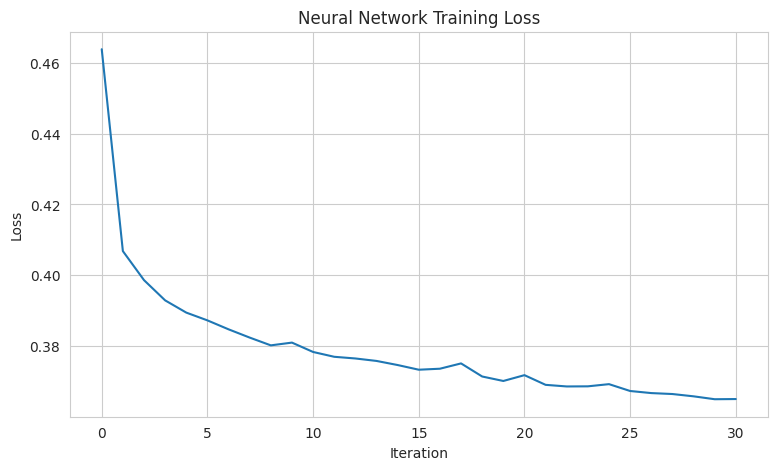

In [ ]:
#Neural Network loss curve
plt.figure(figsize=(9, 5))

plt.plot(
    nn_model.loss_curve_
)

plt.title(
    'Neural Network Training Loss'
)

plt.xlabel('Iteration')
plt.ylabel('Loss')

plt.show()

In [ ]:
#Calculate multiclass AUC for every model
# ============================================================
# MULTICLASS AUC
# ============================================================

number_of_classes = len(
    label_encoder.classes_
)

class_numbers = np.arange(
    number_of_classes
)

y_test_binary = label_binarize(
    y_test,
    classes=class_numbers
)

#calculate weighted multiclass AUC
for model_name in results:

    probabilities = (
        results[model_name][
            'Probability'
        ]
    )

    model_auc = roc_auc_score(
        y_test,
        probabilities,
        multi_class='ovr',
        average='weighted'
    )

    results[model_name]['AUC'] = (
        model_auc
    )

    print(
        model_name,
        "AUC =",
        round(model_auc, 4)
    )





KNN AUC = 0.8842
Logistic Regression AUC = 0.8666
Naive Bayes AUC = 0.7447
Neural Network AUC = 0.9098


In [ ]:
# ============================================================
# ADD MACRO AND BALANCED METRICS
# ============================================================

for model_name, values in results.items():

    predictions = values['Prediction']

    values['Balanced Accuracy'] = balanced_accuracy_score(
        y_test,
        predictions
    )

    values['Macro Precision'] = precision_score(
        y_test,
        predictions,
        average='macro',
        zero_division=0
    )

    values['Macro Recall'] = recall_score(
        y_test,
        predictions,
        average='macro',
        zero_division=0
    )

    values['Macro F1'] = f1_score(
        y_test,
        predictions,
        average='macro',
        zero_division=0
    )

print("Macro and balanced metrics calculated.")

for model_name, values in results.items():

    print(f"\n{model_name}")

    print(
        "Balanced Accuracy:",
        round(values['Balanced Accuracy'], 4)
    )

    print(
        "Macro Precision:",
        round(values['Macro Precision'], 4)
    )

    print(
        "Macro Recall:",
        round(values['Macro Recall'], 4)
    )

    print(
        "Macro F1:",
        round(values['Macro F1'], 4)
    )

Macro and balanced metrics calculated.

KNN
Balanced Accuracy: 0.576
Macro Precision: 0.7468
Macro Recall: 0.576
Macro F1: 0.6032

Logistic Regression
Balanced Accuracy: 0.5007
Macro Precision: 0.5276
Macro Recall: 0.5007
Macro F1: 0.5069

Naive Bayes
Balanced Accuracy: 0.5184
Macro Precision: 0.589
Macro Recall: 0.5184
Macro F1: 0.2935

Neural Network
Balanced Accuracy: 0.5637
Macro Precision: 0.7658
Macro Recall: 0.5637
Macro F1: 0.5896


In [ ]:
#Print supervised model results
for model_name, values in results.items():

    print(
        "\n" + "=" * 60
    )

    print(model_name)

    print("=" * 60)

    print(
        "Accuracy :",
        round(
            values['Accuracy'],
            4
        )
    )

    print(
        "Precision:",
        round(
            values['Precision'],
            4
        )
    )

    print(
        "Recall   :",
        round(
            values['Recall'],
            4
        )
    )

    print(
        "F1 Score :",
        round(
            values['F1'],
            4
        )
    )

    print(
        "AUC      :",
        round(
            values['AUC'],
            4
        )
    )


KNN
Accuracy : 0.8196
Precision: 0.8163
Recall   : 0.8196
F1 Score : 0.8156
AUC      : 0.8842

Logistic Regression
Accuracy : 0.7885
Precision: 0.7818
Recall   : 0.7885
F1 Score : 0.7759
AUC      : 0.8666

Naive Bayes
Accuracy : 0.2718
Precision: 0.875
Recall   : 0.2718
F1 Score : 0.3925
AUC      : 0.7447

Neural Network
Accuracy : 0.8308
Precision: 0.8294
Recall   : 0.8308
F1 Score : 0.8237
AUC      : 0.9098


### 5.6 K-Means Clustering (Unsupervised Learning)
Treat the same features as an unsupervised clustering problem with K-Means, visualize the clusters with PCA, and compare them against the actual reservation status labels.

In [ ]:
#K-Means: Prepare unsupervised input


X_cluster = df_clean.drop(
    columns=['reservation_status']
)

cluster_numeric_features = (
    X_cluster
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)

cluster_categorical_features = (
    X_cluster
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

In [ ]:
#Independent clustering preprocessing

cluster_numeric_transformer = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(
                strategy='median'
            )
        ),
        (
            'scaler',
            StandardScaler()
        )
    ]
)

cluster_categorical_transformer = Pipeline(
    steps=[
        (
            'imputer',
            SimpleImputer(
                strategy='most_frequent'
            )
        ),
        (
            'onehot',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=True
            )
        )
    ]
)

cluster_preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            cluster_numeric_transformer,
            cluster_numeric_features
        ),
        (
            'cat',
            cluster_categorical_transformer,
            cluster_categorical_features
        )
    ]
)

#Trasform
X_cluster_processed = (
    cluster_preprocessor
    .fit_transform(
        X_cluster
    )
)

print(
    "Clustering data shape:",
    X_cluster_processed.shape
)

Clustering data shape: (119210, 579)


In [ ]:
#Reduce dimensionality for K-Means

svd = TruncatedSVD(
    n_components=20,
    random_state=RANDOM_STATE
)

X_cluster_reduced = (
    svd.fit_transform(
        X_cluster_processed
    )
)

print(
    "Reduced clustering shape:",
    X_cluster_reduced.shape
)

print(
    "Explained variance:",
    round(
        svd.explained_variance_ratio_.sum(),
        4
    )
)

Reduced clustering shape: (119210, 20)
Explained variance: 0.8509


SSE values:
K = 2 --> SSE = 2298645.80
K = 3 --> SSE = 2128423.42
K = 4 --> SSE = 1998946.78
K = 5 --> SSE = 1853191.14
K = 6 --> SSE = 1750148.47
K = 7 --> SSE = 1653302.03
K = 8 --> SSE = 1572213.62
K = 9 --> SSE = 1504394.30
K = 10 --> SSE = 1414082.26
K = 11 --> SSE = 1388854.25
K = 12 --> SSE = 1328817.45
K = 13 --> SSE = 1257776.21
K = 14 --> SSE = 1231859.47

Optimal K using Elbow Method = 7


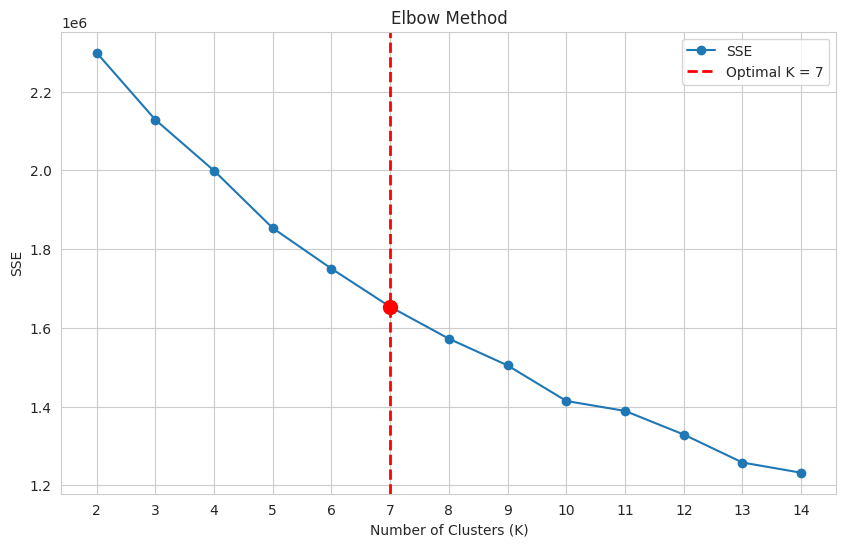

In [ ]:
# ============================================================
# ELBOW METHOD - DETERMINE OPTIMAL K
# ============================================================

from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Try different values of K
# ------------------------------------------------------------

k_values = range(2, 15)

sse = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster_reduced)

    # Inertia = Sum of Squared Errors (SSE)
    sse.append(kmeans.inertia_)


# ------------------------------------------------------------
# 2. Convert K and SSE values to NumPy arrays
# ------------------------------------------------------------

k_array = np.array(list(k_values))

sse_array = np.array(sse)


# ------------------------------------------------------------
# 3. Automatically find the elbow point
#
# Method:
# Find the point having the maximum perpendicular distance
# from the straight line between the first and last points.
# ------------------------------------------------------------

points = np.column_stack(
    (k_array, sse_array)
)


# Normalize the data because K and SSE have very different scales
normalized_points = (
    (points - points.min(axis=0))
    /
    (points.max(axis=0) - points.min(axis=0))
)


# First and last points
first_point = normalized_points[0]

last_point = normalized_points[-1]


# Vector representing straight line
line_vector = (
    last_point - first_point
)

line_vector = (
    line_vector
    /
    np.linalg.norm(line_vector)
)


# Vectors from first point to every point
vectors = (
    normalized_points - first_point
)


# Projection of each point onto the straight line
projections = np.outer(
    np.dot(
        vectors,
        line_vector
    ),
    line_vector
)


# Perpendicular distance from straight line
distances = np.linalg.norm(
    vectors - projections,
    axis=1
)


# Point with maximum distance is selected as elbow
elbow_index = np.argmax(
    distances
)

optimal_k = int(
    k_array[elbow_index]
)


# ------------------------------------------------------------
# 4. Print SSE values and selected K
# ------------------------------------------------------------

print("SSE values:")

for k, value in zip(
    k_array,
    sse_array
):

    print(
        f"K = {k} --> SSE = {value:.2f}"
    )


print("\n" + "=" * 45)

print(
    "Optimal K using Elbow Method =",
    optimal_k
)

print("=" * 45)


# ------------------------------------------------------------
# 5. Plot Elbow Method graph
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)


plt.plot(
    k_array,
    sse_array,
    marker='o',
    linestyle='-',
    label='SSE'
)


# Red vertical dashed line at optimal K
plt.axvline(
    x=optimal_k,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Optimal K = {optimal_k}'
)


# Highlight elbow point
plt.scatter(
    optimal_k,
    sse_array[elbow_index],
    color='red',
    s=100,
    zorder=5
)


plt.title(
    'Elbow Method'
)

plt.xlabel(
    'Number of Clusters (K)'
)

plt.ylabel(
    'SSE'
)

plt.xticks(
    k_array
)

plt.grid(True)

plt.legend()

plt.show()

In [ ]:
# ============================================================
# FINAL K-MEANS CLUSTERING USING ELBOW K
# ============================================================

final_kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = final_kmeans.fit_predict(
    X_cluster_reduced
)


print(
    "Selected number of clusters (K):",
    optimal_k
)

print(
    "\nCluster distribution:"
)

unique_clusters, cluster_counts = np.unique(
    cluster_labels,
    return_counts=True
)

for cluster, count in zip(
    unique_clusters,
    cluster_counts
):

    print(
        f"Cluster {cluster}: {count} samples"
    )

Selected number of clusters (K): 7

Cluster distribution:
Cluster 0: 15664 samples
Cluster 1: 8344 samples
Cluster 2: 38389 samples
Cluster 3: 52045 samples
Cluster 4: 145 samples
Cluster 5: 917 samples
Cluster 6: 3706 samples


In [ ]:
#Add Cluster Labels to Dataset
# ============================================================
# ADD CLUSTER LABELS
# ============================================================

clustered_df = df_clean.copy()

clustered_df['Cluster'] = cluster_labels

display(
    clustered_df[
        [
            'reservation_status',
            'Cluster'
        ]
    ].head()
)


,reservation_status,Cluster
0,Check-Out,2
1,Check-Out,2
2,Check-Out,2
3,Check-Out,2
4,Check-Out,2


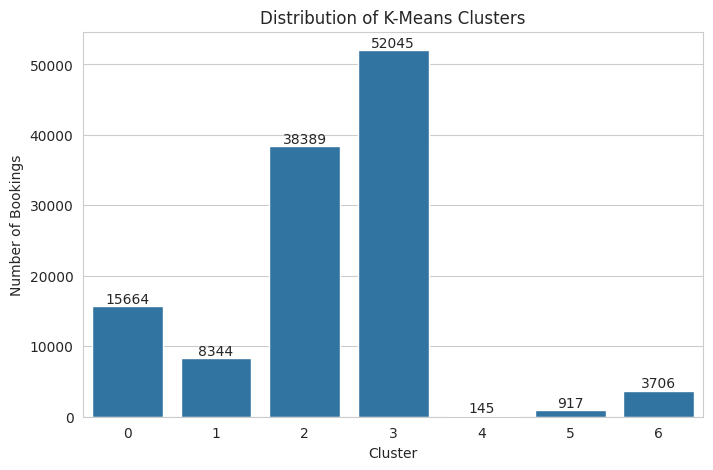

In [ ]:
#— Cluster Distribution Bar Chart
# ============================================================
# CLUSTER DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(8, 5)
)

ax = sns.countplot(
    data=clustered_df,
    x='Cluster'
)

plt.title(
    'Distribution of K-Means Clusters'
)

plt.xlabel(
    'Cluster'
)

plt.ylabel(
    'Number of Bookings'
)

for container in ax.containers:

    ax.bar_label(
        container
    )

plt.show()

In [ ]:
#PCA Visualization
# ============================================================
# PCA VISUALIZATION
# ============================================================

from sklearn.decomposition import PCA

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(
    X_cluster_reduced
)

print(
    "Explained variance ratio:"
)

print(
    pca.explained_variance_ratio_
)

print(
    "\nTotal explained variance:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

Explained variance ratio:
[0.15059485 0.11244266]

Total explained variance: 0.263


PCA Explained Variance Ratio:
[0.15059485 0.11244266]
Total Explained Variance: 0.263

Reservation Status Mapping:
0 = Canceled
1 = Check-Out
2 = No-Show

Total data points: 119210
Data points shown in zoomed graph: 110340
Extreme points hidden only from graph: 8870


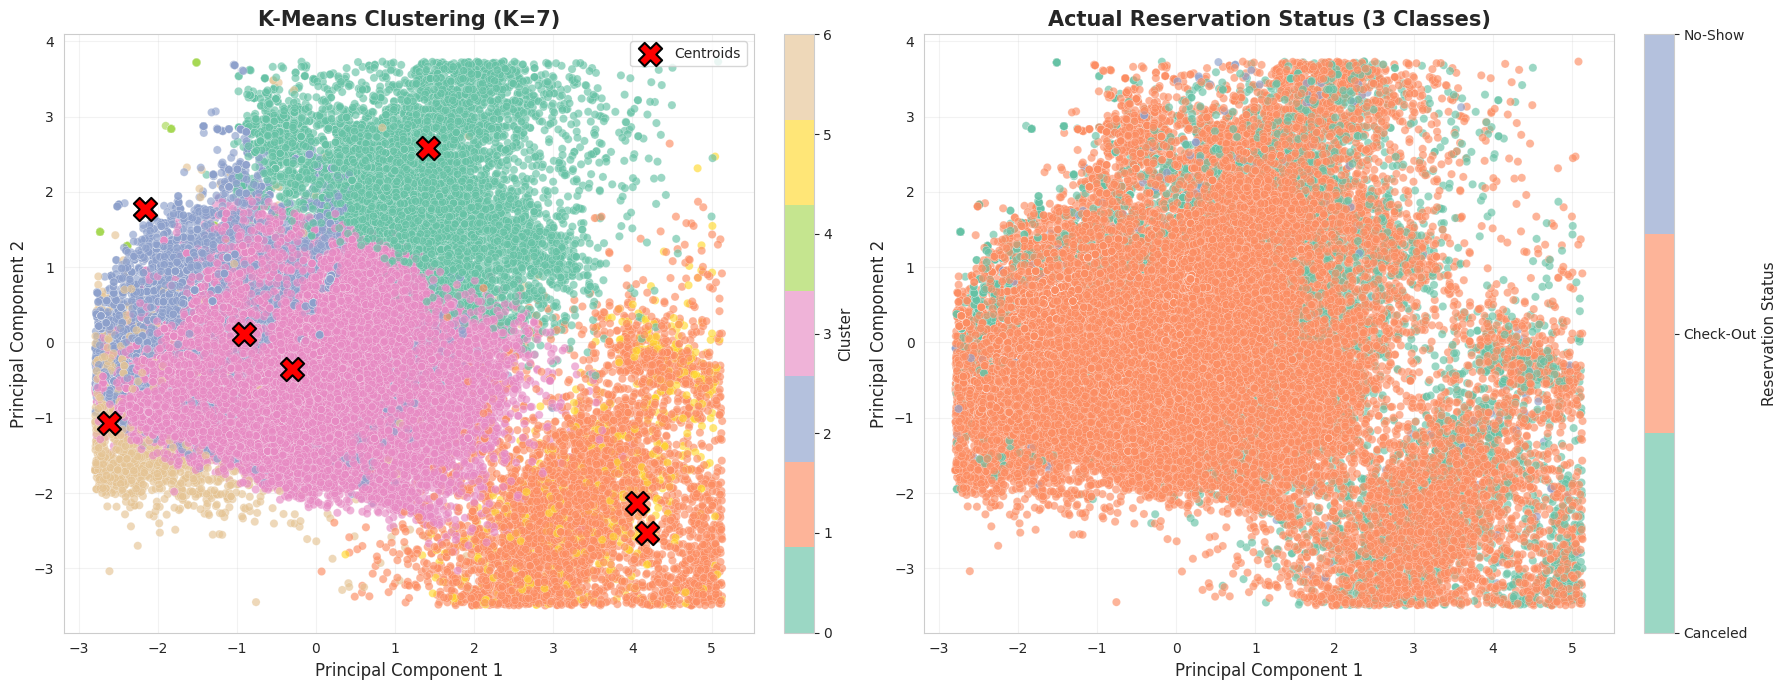

In [ ]:

# K-MEANS CLUSTERING VISUALIZATION (CLEAR & ZOOMED IN)

# LEFT  : K-Means Clusters with Centroids
# RIGHT : Actual Reservation Status


import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
from matplotlib.colors import ListedColormap



# 1. PCA: REDUCE CLUSTERING DATA TO 2 DIMENSIONS


pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(
    X_cluster_reduced
)


print("PCA Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "Total Explained Variance:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)



# 2. TRANSFORM K-MEANS CENTROIDS INTO PCA SPACE


centers_pca = pca.transform(
    final_kmeans.cluster_centers_
)



# 3. ENCODE ACTUAL RESERVATION STATUS FOR COLORING


status_encoder = LabelEncoder()

actual_status = status_encoder.fit_transform(
    clustered_df['reservation_status']
)


print("\nReservation Status Mapping:")

for i, status in enumerate(
    status_encoder.classes_
):
    print(f"{i} = {status}")



# 4. REMOVE EXTREME PCA OUTLIERS FROM DISPLAY ONLY


x_low, x_high = np.percentile(
    X_pca[:, 0],
    [2, 98]
)

y_low, y_high = np.percentile(
    X_pca[:, 1],
    [2, 98]
)


plot_mask = (
    (X_pca[:, 0] >= x_low) &
    (X_pca[:, 0] <= x_high) &
    (X_pca[:, 1] >= y_low) &
    (X_pca[:, 1] <= y_high)
)


X_plot = X_pca[
    plot_mask
]

cluster_plot = cluster_labels[
    plot_mask
]

status_plot = actual_status[
    plot_mask
]


print("\nTotal data points:", len(X_pca))

print(
    "Data points shown in zoomed graph:",
    len(X_plot)
)

print(
    "Extreme points hidden only from graph:",
    len(X_pca) - len(X_plot)
)



# 5. DEFINE DISTINCT COLORS FOR K-MEANS CLUSTERS


cluster_colors = [
    '#66c2a5',   # Cluster 0 - Green
    '#fc8d62',   # Cluster 1 - Orange
    '#8da0cb',   # Cluster 2 - Blue
    '#e78ac3',   # Cluster 3 - Pink
    '#a6d854',   # Cluster 4 - Light Green
    '#ffd92f',   # Cluster 5 - Yellow
    '#e5c494',   # Cluster 6 - Beige
    '#b3b3b3'    # Cluster 7 - Gray
]


# Use only the number of colors required by optimal_k
cluster_cmap = ListedColormap(
    cluster_colors[:optimal_k]
)



# 6. DEFINE COLORS FOR ACTUAL RESERVATION STATUS


status_colors = [
    '#66c2a5',
    '#fc8d62',
    '#8da0cb',
    '#e78ac3',
    '#a6d854',
    '#ffd92f',
    '#e5c494',
    '#b3b3b3'
]


status_cmap = ListedColormap(
    status_colors[
        :len(status_encoder.classes_)
    ]
)


# ============================================================
# 7. CREATE SIDE-BY-SIDE FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 7)
)


# ============================================================
# LEFT GRAPH: K-MEANS CLUSTERS
# ============================================================

scatter1 = axes[0].scatter(

    X_plot[:, 0],
    X_plot[:, 1],

    c=cluster_plot,

    cmap=cluster_cmap,

    s=35,

    alpha=0.65,

    edgecolors='white',

    linewidths=0.2
)


# ============================================================
# 8. PLOT CENTROIDS
# ============================================================

axes[0].scatter(

    centers_pca[:, 0],
    centers_pca[:, 1],

    c='red',

    marker='X',

    s=280,

    edgecolors='black',

    linewidths=1.5,

    label='Centroids',

    zorder=10
)


axes[0].set_title(
    f'K-Means Clustering (K={optimal_k})',
    fontsize=15,
    fontweight='bold'
)

axes[0].set_xlabel(
    'Principal Component 1',
    fontsize=12
)

axes[0].set_ylabel(
    'Principal Component 2',
    fontsize=12
)

axes[0].grid(
    True,
    alpha=0.25
)

axes[0].legend(
    loc='upper right'
)


# ============================================================
# 9. LEFT COLORBAR
# ============================================================

cluster_ticks = np.arange(
    optimal_k
)

cbar1 = fig.colorbar(

    scatter1,

    ax=axes[0],

    ticks=cluster_ticks,

    fraction=0.046,

    pad=0.04
)

cbar1.set_label(
    'Cluster',
    fontsize=11
)

cbar1.set_ticklabels(
    [
        str(i)
        for i in cluster_ticks
    ]
)


# ============================================================
# RIGHT GRAPH: ACTUAL RESERVATION STATUS
# ============================================================

scatter2 = axes[1].scatter(

    X_plot[:, 0],
    X_plot[:, 1],

    c=status_plot,

    cmap=status_cmap,

    s=35,

    alpha=0.65,

    edgecolors='white',

    linewidths=0.2
)


axes[1].set_title(

    f'Actual Reservation Status '
    f'({len(status_encoder.classes_)} Classes)',

    fontsize=15,

    fontweight='bold'
)

axes[1].set_xlabel(
    'Principal Component 1',
    fontsize=12
)

axes[1].set_ylabel(
    'Principal Component 2',
    fontsize=12
)

axes[1].grid(
    True,
    alpha=0.25
)


# ============================================================
# 10. RIGHT COLORBAR
# ============================================================

status_ticks = np.arange(
    len(status_encoder.classes_)
)

cbar2 = fig.colorbar(

    scatter2,

    ax=axes[1],

    ticks=status_ticks,

    fraction=0.046,

    pad=0.04
)

cbar2.set_label(
    'Reservation Status',
    fontsize=11
)

cbar2.set_ticklabels(
    status_encoder.classes_
)


# ============================================================
# 11. SAME ZOOM FOR BOTH GRAPHS
# ============================================================

x_margin = (
    x_high - x_low
) * 0.05

y_margin = (
    y_high - y_low
) * 0.05


for ax in axes:

    ax.set_xlim(
        x_low - x_margin,
        x_high + x_margin
    )

    ax.set_ylim(
        y_low - y_margin,
        y_high + y_margin
    )


# ============================================================
# 12. FINAL LAYOUT
# ============================================================

plt.tight_layout()

plt.show()

reservation_status,Canceled,Check-Out,No-Show
Cluster,,,
0,5105,10371,188
1,2998,5256,90
2,16259,21851,279
3,17831,33617,597
4,144,1,0
5,159,750,8
6,497,3165,44


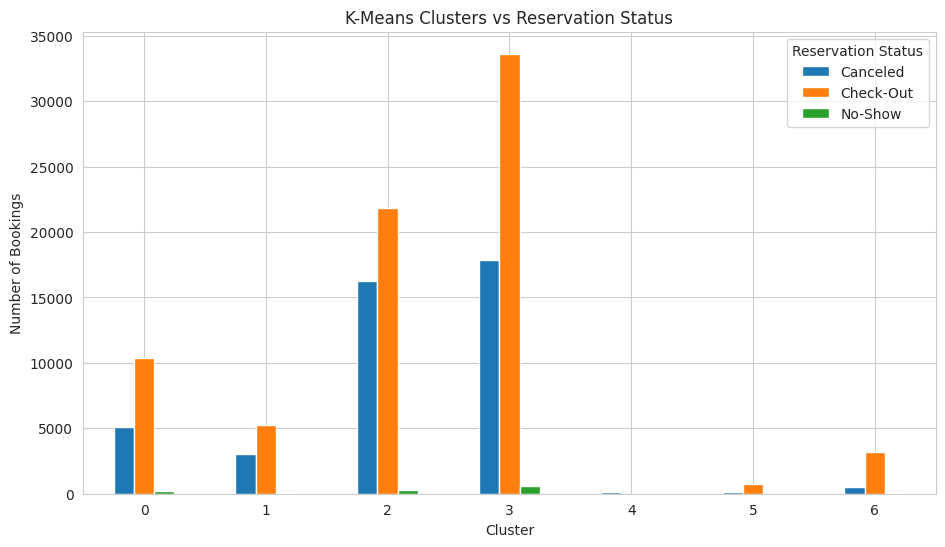

In [ ]:
#Compare Clusters With reservation_status
# ============================================================
# CLUSTERS VS RESERVATION STATUS
# ============================================================

cluster_vs_status = pd.crosstab(
    clustered_df['Cluster'],
    clustered_df['reservation_status']
)

display(
    cluster_vs_status
)


#plot
cluster_vs_status.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title(
    'K-Means Clusters vs Reservation Status'
)

plt.xlabel(
    'Cluster'
)

plt.ylabel(
    'Number of Bookings'
)

plt.xticks(
    rotation=0
)

plt.legend(
    title='Reservation Status'
)

plt.show()

In [ ]:
#Cluster Profiles
# ============================================================
# CLUSTER PROFILE
# ============================================================

cluster_profile = (
    clustered_df
    .groupby('Cluster')[
        [
            'lead_time',
            'adr',
            'total_nights',
            'total_guests',
            'previous_cancellations',
            'booking_changes',
            'total_of_special_requests'
        ]
    ]
    .mean()
    .round(2)
)

display(
    cluster_profile
)

,lead_time,adr,total_nights,total_guests,previous_cancellations,booking_changes,total_of_special_requests
Cluster,,,,,,,
0,136.03,103.48,8.03,1.97,0.02,0.33,0.71
1,90.11,159.19,3.87,3.45,0.01,0.34,0.86
2,135.64,86.26,2.61,1.77,0.11,0.18,0.36
3,78.91,106.45,2.67,1.90,0.01,0.18,0.62
4,229.70,58.15,3.87,2.00,21.98,0.01,0.00
5,77.63,119.83,4.16,3.25,0.01,0.88,1.54
6,29.65,63.85,1.77,1.40,0.46,0.25,0.61


In [ ]:
# ============================================================
# FINAL MODEL COMPARISON TABLE
# ============================================================

comparison_df = pd.DataFrame({

    model_name: {
        'Accuracy': values['Accuracy'],

        'Balanced Accuracy':
            values['Balanced Accuracy'],

        'Weighted Precision':
            values['Precision'],

        'Weighted Recall':
            values['Recall'],

        'Weighted F1':
            values['F1'],

        'Macro Precision':
            values['Macro Precision'],

        'Macro Recall':
            values['Macro Recall'],

        'Macro F1':
            values['Macro F1'],

        'Weighted AUC':
            values['AUC']
    }

    for model_name, values in results.items()

}).T

display(
    comparison_df.round(4)
)

,Accuracy,Balanced Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro Precision,Macro Recall,Macro F1,Weighted AUC
KNN,0.8196,0.5760,0.8163,0.8196,0.8156,0.7468,0.5760,0.6032,0.8842
Logistic Regression,0.7885,0.5007,0.7818,0.7885,0.7759,0.5276,0.5007,0.5069,0.8666
Naive Bayes,0.2718,0.5184,0.8750,0.2718,0.3925,0.5890,0.5184,0.2935,0.7447
Neural Network,0.8308,0.5637,0.8294,0.8308,0.8237,0.7658,0.5637,0.5896,0.9098


## 6. Model Selection / Comparison Analysis
Compare all trained models using accuracy, precision, recall, F1-score, confusion matrices, and ROC/AUC curves.

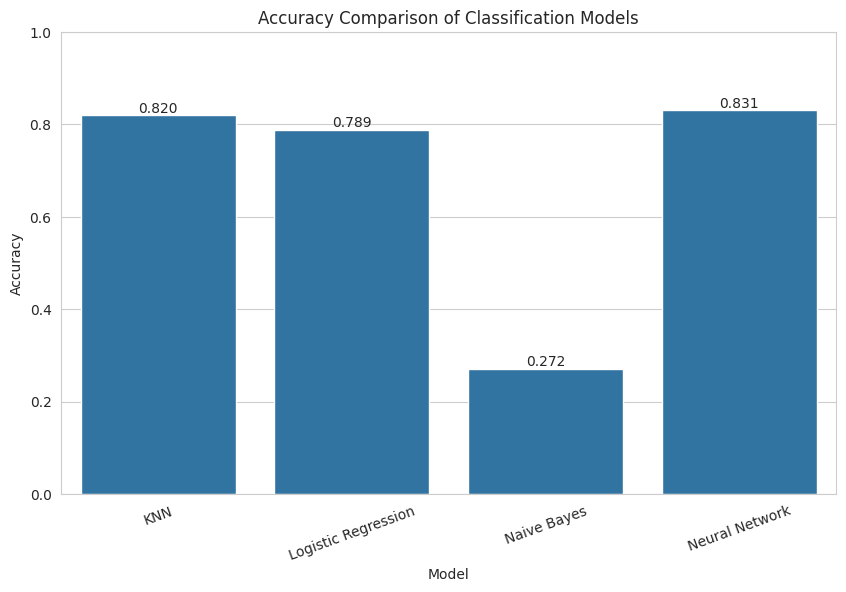

In [ ]:
#Accuracy Bar Chart
# ============================================================
# ACCURACY COMPARISON
# ============================================================

plt.figure(
    figsize=(10, 6)
)

ax = sns.barplot(
    x=comparison_df.index,
    y=comparison_df['Accuracy']
)

plt.title(
    'Accuracy Comparison of Classification Models'
)

plt.xlabel(
    'Model'
)

plt.ylabel(
    'Accuracy'
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=20
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt='%.3f'
    )

plt.show()

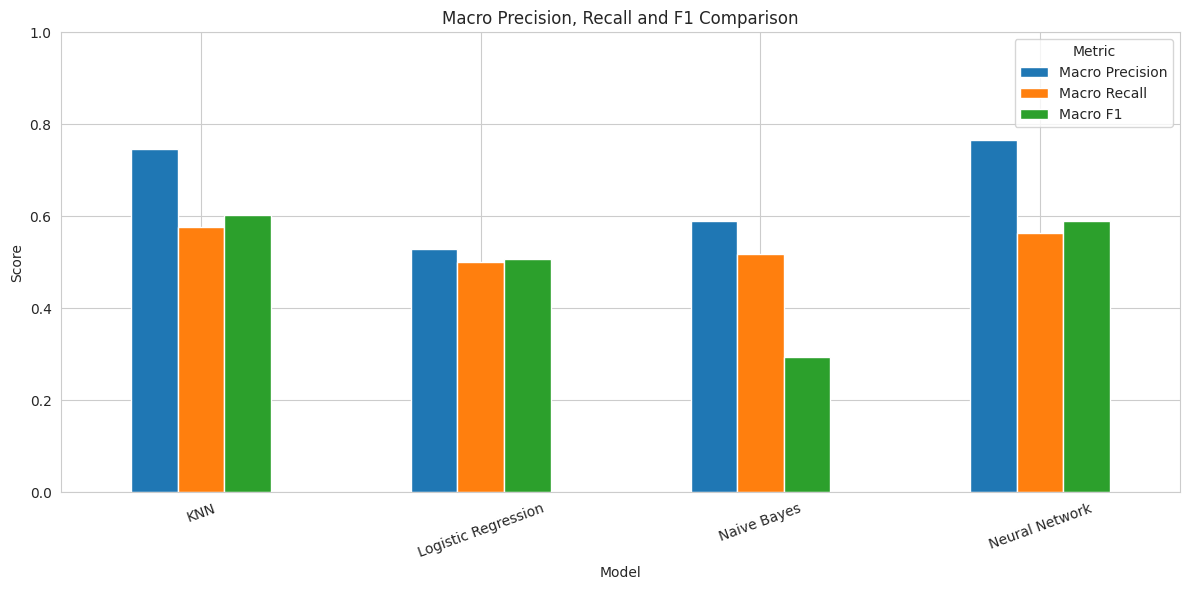

In [ ]:
# ============================================================
# MACRO PRECISION, RECALL AND F1 COMPARISON
# ============================================================

comparison_df[
    [
        'Macro Precision',
        'Macro Recall',
        'Macro F1'
    ]
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title(
    'Macro Precision, Recall and F1 Comparison'
)

plt.xlabel('Model')
plt.ylabel('Score')

plt.ylim(0, 1)

plt.xticks(
    rotation=20
)

plt.legend(
    title='Metric'
)

plt.tight_layout()
plt.show()

In [ ]:
#Classification Report


for model_name, values in results.items():

    print(
        "\n" + "=" * 70
    )

    print(
        model_name
    )

    print(
        "=" * 70
    )

    print(
        classification_report(
            y_test,
            values['Prediction'],
            target_names=
                label_encoder.classes_,
            zero_division=0
        )
    )


KNN
              precision    recall  f1-score   support

    Canceled       0.78      0.73      0.75      8599
   Check-Out       0.84      0.88      0.86     15002
     No-Show       0.62      0.12      0.20       241

    accuracy                           0.82     23842
   macro avg       0.75      0.58      0.60     23842
weighted avg       0.82      0.82      0.82     23842


Logistic Regression
              precision    recall  f1-score   support

    Canceled       0.80      0.58      0.67      8599
   Check-Out       0.79      0.92      0.85     15002
     No-Show       0.00      0.00      0.00       241

    accuracy                           0.79     23842
   macro avg       0.53      0.50      0.51     23842
weighted avg       0.78      0.79      0.78     23842


Naive Bayes
              precision    recall  f1-score   support

    Canceled       0.85      0.39      0.54      8599
   Check-Out       0.90      0.19      0.32     15002
     No-Show       0.01      0.97   

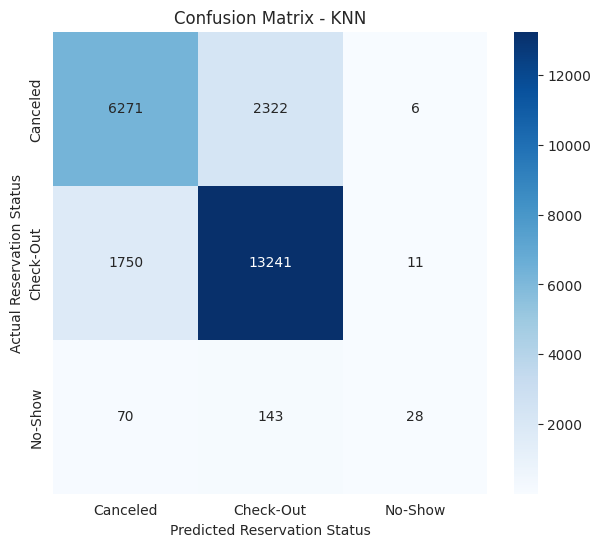

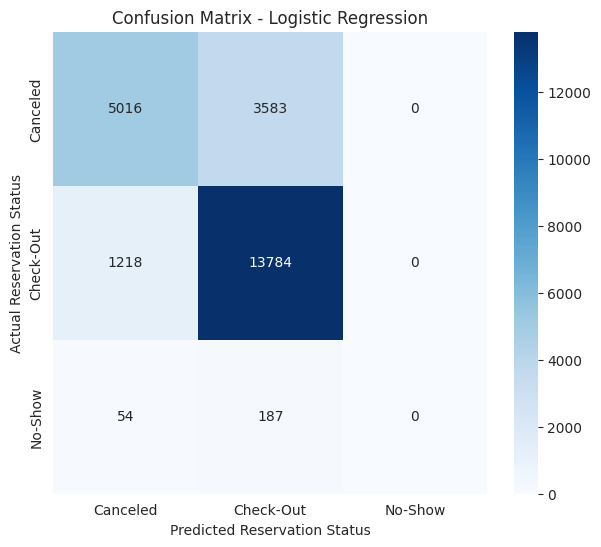

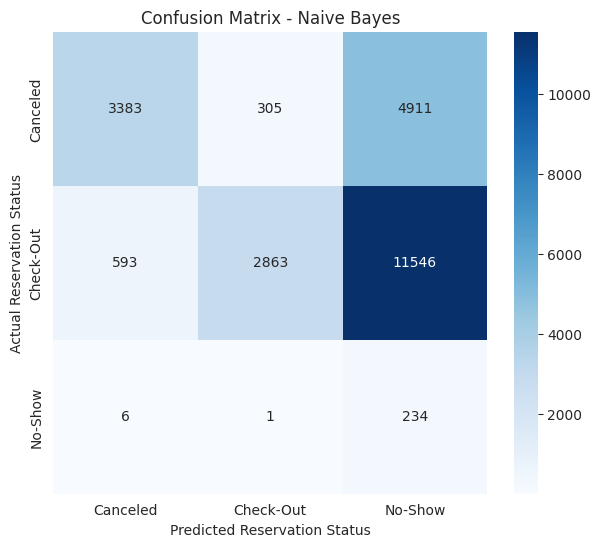

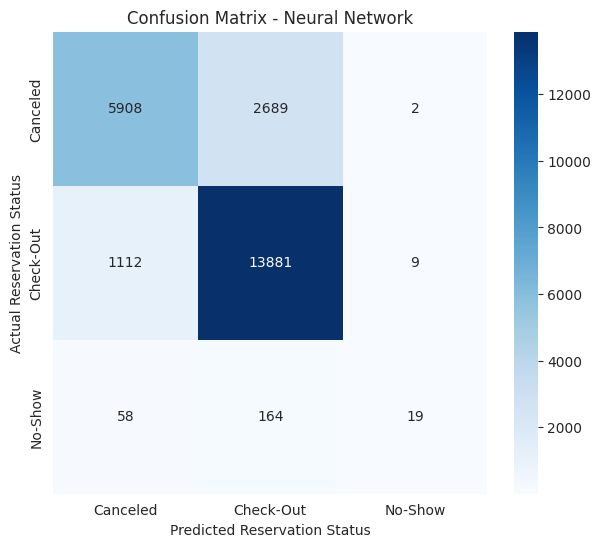

In [ ]:
#Confusion Matrix for Every Model
# ============================================================
# CONFUSION MATRICES
# ============================================================

for model_name, values in results.items():

    cm = confusion_matrix(
        y_test,
        values['Prediction']
    )

    plt.figure(
        figsize=(7, 6)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=
            label_encoder.classes_,
        yticklabels=
            label_encoder.classes_
    )

    plt.title(
        f'Confusion Matrix - {model_name}'
    )

    plt.xlabel(
        'Predicted Reservation Status'
    )

    plt.ylabel(
        'Actual Reservation Status'
    )

    plt.show()

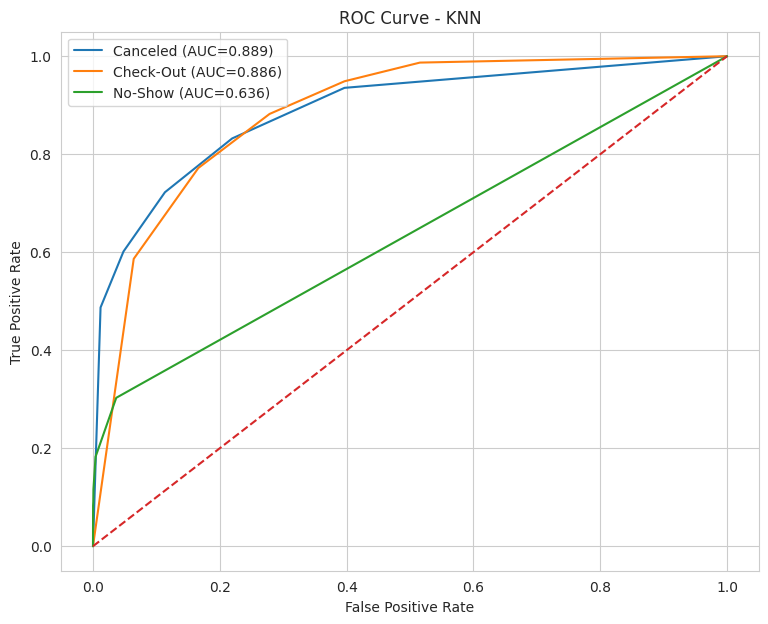

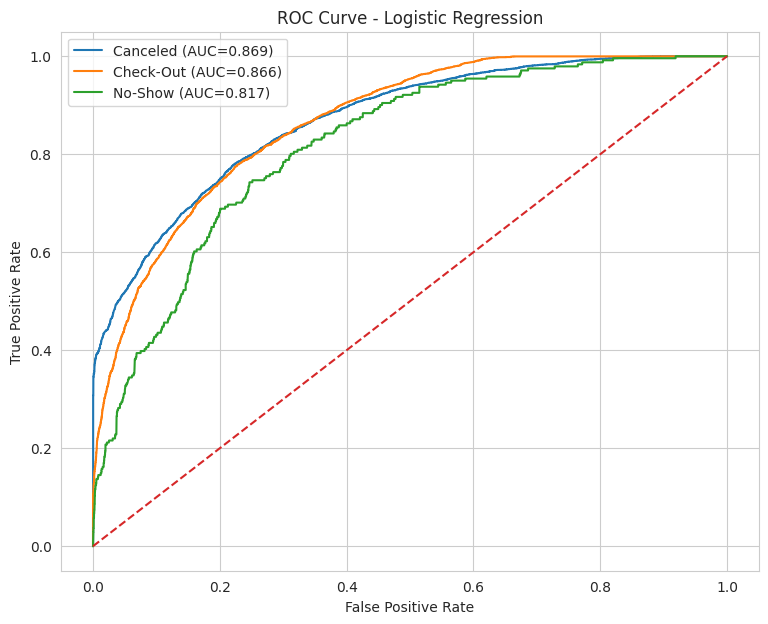

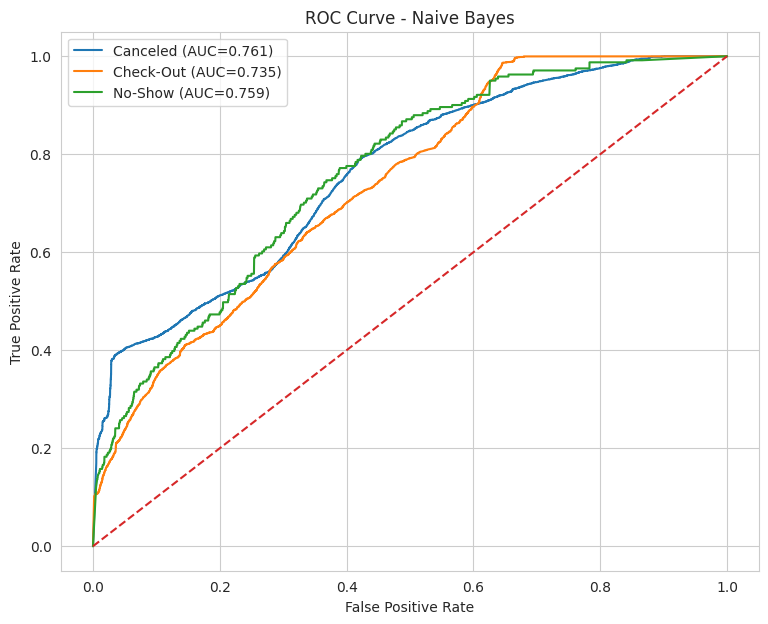

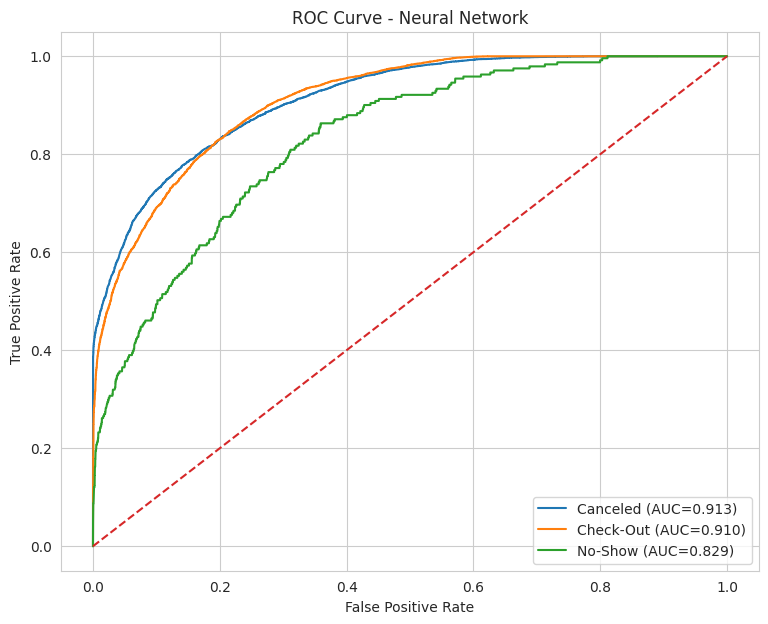

In [ ]:
#Multiclass ROC Curves
# ============================================================
# MULTICLASS ROC CURVES
# ============================================================

for model_name, values in results.items():

    probabilities = (
        values['Probability']
    )

    plt.figure(
        figsize=(9, 7)
    )

    for class_index, class_name in enumerate(
        label_encoder.classes_
    ):

        fpr, tpr, _ = roc_curve(
            y_test_binary[
                :,
                class_index
            ],
            probabilities[
                :,
                class_index
            ]
        )

        class_auc = auc(
            fpr,
            tpr
        )

        plt.plot(
            fpr,
            tpr,
            label=
                f'{class_name} '
                f'(AUC={class_auc:.3f})'
        )

    plt.plot(
        [0, 1],
        [0, 1],
        '--'
    )

    plt.title(
        f'ROC Curve - {model_name}'
    )

    plt.xlabel(
        'False Positive Rate'
    )

    plt.ylabel(
        'True Positive Rate'
    )

    plt.legend()

    plt.show()

In [ ]:
# ============================================================
# SORT MODEL PERFORMANCE
# ============================================================

comparison_df = comparison_df.sort_values(
    by='Macro F1',
    ascending=False
)

print(
    "Models sorted from highest to lowest Macro F1:"
)

display(
    comparison_df.round(4)
)

Models sorted from highest to lowest Macro F1:


,Accuracy,Balanced Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro Precision,Macro Recall,Macro F1,Weighted AUC
KNN,0.8196,0.5760,0.8163,0.8196,0.8156,0.7468,0.5760,0.6032,0.8842
Neural Network,0.8308,0.5637,0.8294,0.8308,0.8237,0.7658,0.5637,0.5896,0.9098
Logistic Regression,0.7885,0.5007,0.7818,0.7885,0.7759,0.5276,0.5007,0.5069,0.8666
Naive Bayes,0.2718,0.5184,0.8750,0.2718,0.3925,0.5890,0.5184,0.2935,0.7447


In [ ]:
# ============================================================
# FIND BEST MODEL
# ============================================================

best_model_macro_f1 = (
    comparison_df['Macro F1'].idxmax()
)

best_model_accuracy = (
    comparison_df['Accuracy'].idxmax()
)

best_model_auc = (
    comparison_df['Weighted AUC'].idxmax()
)

print(
    "Best model by Macro F1:",
    best_model_macro_f1
)

print(
    "Best model by Accuracy:",
    best_model_accuracy
)

print(
    "Best model by Weighted AUC:",
    best_model_auc
)

print(
    "\nUse Macro F1 as the main model-selection metric "
    "because the target classes are highly imbalanced."
)

Best model by Macro F1: KNN
Best model by Accuracy: Neural Network
Best model by Weighted AUC: Neural Network

Use Macro F1 as the main model-selection metric because the target classes are highly imbalanced.
